# Mancala AI Agent Analysis
## AI 801 — Group 8: Shuyang Huang, Elliott Armstrong, Matthew Kolker
### Penn State University, Spring 2026

This notebook provides a comprehensive analysis of AI game-playing agents in Mancala (Kalah variant). 


## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats, optimize
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

import re
from matplotlib.path import Path
from matplotlib.patches import PathPatch

plt.rcParams.update({
    'figure.figsize': (12, 6), 'figure.dpi': 120,
    'font.size': 11, 'font.family': 'serif',
    'axes.titlesize': 13, 'axes.labelsize': 11,
    'legend.fontsize': 9, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.grid': True, 'grid.alpha': 0.3,
})

def pw(df,a,b):
    sub=df[((df['p1_label']==a)&(df['p2_label']==b))|((df['p1_label']==b)&(df['p2_label']==a))]
    if len(sub)==0: return None
    aw=((sub['p1_label']==a)&(sub['winner']=='p1')).sum()+((sub['p2_label']==a)&(sub['winner']=='p2')).sum()
    dr=(sub['winner']=='draw').sum();n=len(sub)
    return {'aw':aw,'bw':n-aw-dr,'dr':dr,'n':n,'wr':aw/n,'ci':wilson_ci(aw,n)}

def logistic(x,a,b): return 1/(1+np.exp(-(a*x+b)))

COLORS = plt.cm.tab20.colors
REF_BENCHMARK = 106.975  # machine_A benchmark for timing normalization


## 1. Data Loading & Validation

In [2]:
# Load both engine versions
v2 = pd.read_csv('data/mancala_results.csv')

# Timing normalization for v2
v2['norm_factor'] = REF_BENCHMARK / v2['benchmark_ms']
v2['p1_avg_time_norm'] = v2['p1_avg_time'] * v2['norm_factor']
v2['p2_avg_time_norm'] = v2['p2_avg_time'] * v2['norm_factor']

print(f"v2: {len(v2):,} games, {v2['matchup_label'].nunique()} matchups, "
      f"{len(set(v2['p1_label']) | set(v2['p2_label']))} agents")
print(f"\nv2 machines: {v2.groupby('machine_id')['benchmark_ms'].first().to_dict()}")


v2: 9,408 games, 117 matchups, 30 agents

v2 machines: {'machine_A': 106.975, 'machine_B': 96.088}


In [3]:
# Validate matchup counts (all should be multiples of 50)
mc = v2.groupby('matchup_label').size().sort_values(ascending=False)
non_50 = mc[mc % 50 != 0]
if len(non_50) == 0:
    print("All matchup counts are multiples of 50.")
else:
    print(f"WARNING: {len(non_50)} matchups are NOT multiples of 50:")
    print(non_50)

print(f"\nMatchup size distribution:")
print(mc.value_counts().sort_index().to_string())


matchup_label
MCTS(n=2000) vs MCTS(n=10000)     112
MCTS(n=2000) vs MCTS(n=100000)     46
dtype: int64

Matchup size distribution:
46      1
50     66
100    34
112     1
150     9
200     6


In [4]:
# Matchup coverage prep
sns.set_theme(style="white")

def agent_family(agent):
    if agent == "Random":
        return "Random"
    if agent == "Greedy":
        return "Greedy"
    if "Minimax" in agent:
        return "Minimax"
    if "Alpha-Beta" in agent:
        return "Alpha-Beta"
    if "MCTS" in agent:
        return "MCTS"
    return "Other"

def agent_sort_key(agent):
    family_order = {
        "Random": 0,
        "Greedy": 1,
        "Minimax": 2,
        "Alpha-Beta": 3,
        "MCTS": 4,
        "Other": 5,
    }
    fam = agent_family(agent)

    depth_match = re.search(r"d=(\d+)", agent)
    sim_match = re.search(r"n=(\d+)", agent)
    c_match = re.search(r"C=([0-9.]+)", agent)
    rich_flag = 1 if "rich" in agent else 0

    depth = int(depth_match.group(1)) if depth_match else -1
    sims = int(sim_match.group(1)) if sim_match else -1
    c_val = float(c_match.group(1)) if c_match else -1.0

    return (family_order[fam], depth, sims, c_val, rich_flag, agent)

def family_color(agent):
    fam = agent_family(agent)
    return {
        "Random": "#6b6b6b",
        "Greedy": "#9ecae1",
        "Minimax": "#6baed6",
        "Alpha-Beta": "#2171b5",
        "MCTS": "#e6550d",
        "Other": "#999999",
    }[fam]

# All agents in a fixed display order
agents = sorted(set(v2["p1_label"]) | set(v2["p2_label"]), key=agent_sort_key)

# Unordered matchup table
matchups = v2.copy()
matchups["agent_a"] = matchups.apply(
    lambda r: min(r["p1_label"], r["p2_label"], key=agent_sort_key), axis=1
)
matchups["agent_b"] = matchups.apply(
    lambda r: max(r["p1_label"], r["p2_label"], key=agent_sort_key), axis=1
)

pair_counts = (
    matchups.groupby(["agent_a", "agent_b"])
    .size()
    .reset_index(name="n_games")
)

pair_counts.head()


,agent_a,agent_b,n_games
0,Alpha-Beta(d=3),Alpha-Beta(d=3),50
1,Alpha-Beta(d=4),Alpha-Beta(d=4),100
2,Alpha-Beta(d=4),"Alpha-Beta(d=4,rich)",50
3,Alpha-Beta(d=4),Alpha-Beta(d=6),150
4,Alpha-Beta(d=4),Alpha-Beta(d=8),150


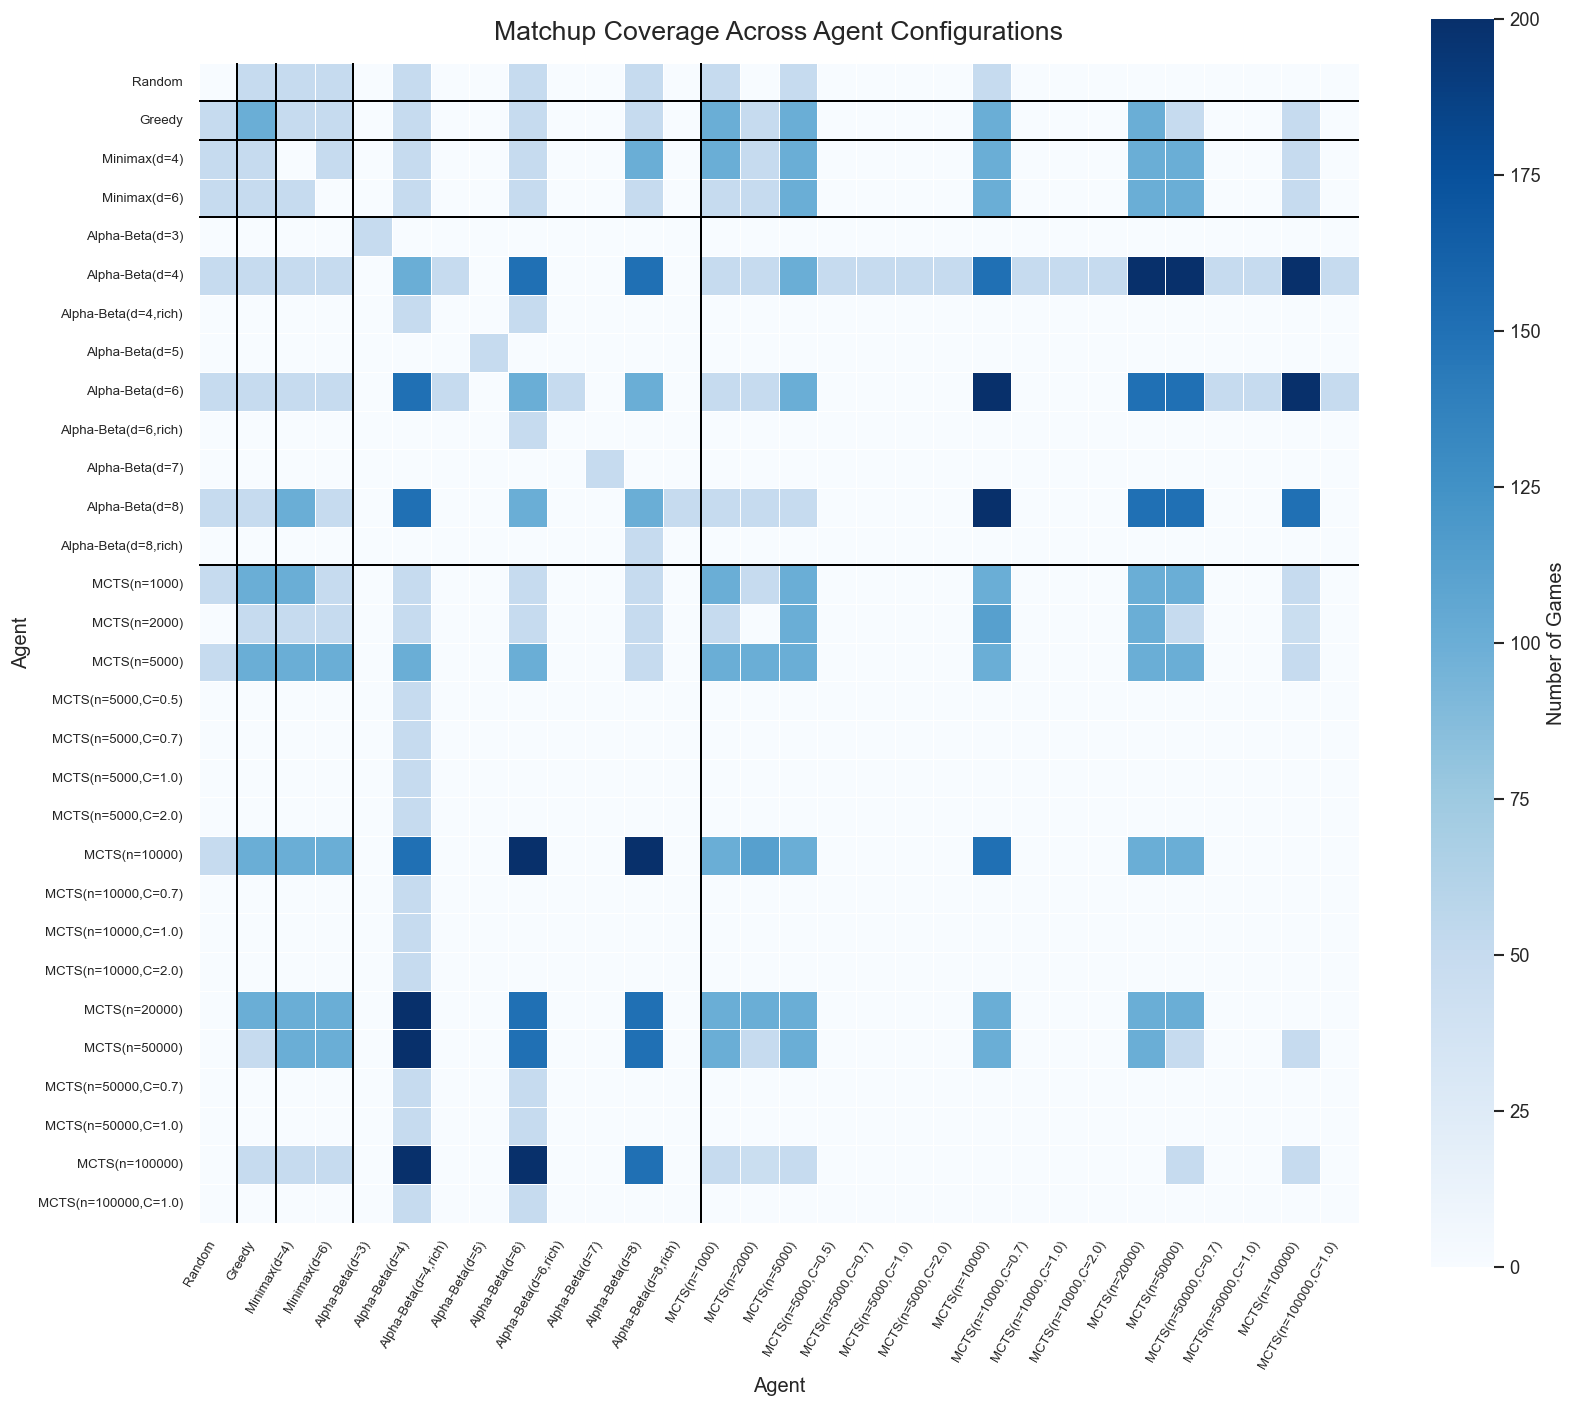

In [5]:
# Matchup coverage heatmap
coverage = pd.DataFrame(0, index=agents, columns=agents, dtype=int)

for _, row in pair_counts.iterrows():
    a, b, n = row["agent_a"], row["agent_b"], row["n_games"]
    coverage.loc[a, b] = n
    coverage.loc[b, a] = n

fig, ax = plt.subplots(figsize=(14, 12))

sns.heatmap(
    coverage,
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar_kws={"label": "Number of Games"},
    ax=ax
)

ax.set_title("Matchup Coverage Across Agent Configurations", fontsize=16, pad=14)
ax.set_xlabel("Agent")
ax.set_ylabel("Agent")
ax.set_xticklabels(ax.get_xticklabels(), rotation=60, ha="right", fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)

# Family separators
family_blocks = []
current_family = None
start_idx = 0

for i, agent in enumerate(agents):
    fam = agent_family(agent)
    if current_family is None:
        current_family = fam
        start_idx = i
    elif fam != current_family:
        family_blocks.append((current_family, start_idx, i - 1))
        current_family = fam
        start_idx = i
family_blocks.append((current_family, start_idx, len(agents) - 1))

for _, start, end in family_blocks[:-1]:
    boundary = end + 1
    ax.axhline(boundary, color="black", linewidth=1.2)
    ax.axvline(boundary, color="black", linewidth=1.2)

plt.tight_layout()
plt.show()


## 2. Helper Functions

In [6]:
def wilson_ci(wins, n, z=1.96):
    """Wilson score confidence interval for a binomial proportion."""
    if n == 0: return 0.0, 0.0, 0.0
    p = wins / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / denom
    spread = z * np.sqrt((p*(1-p) + z**2/(4*n)) / n) / denom
    return p, max(0, center - spread), min(1, center + spread)

def pairwise_result(df, agent_a, agent_b):
    """Get wins/losses/draws for agent_a vs agent_b from either seat."""
    sub = df[((df['p1_label'] == agent_a) & (df['p2_label'] == agent_b)) |
             ((df['p1_label'] == agent_b) & (df['p2_label'] == agent_a))]
    if len(sub) == 0: return None
    a_wins = ((sub['p1_label'] == agent_a) & (sub['winner'] == 'p1')).sum() + \
             ((sub['p2_label'] == agent_a) & (sub['winner'] == 'p2')).sum()
    b_wins = len(sub) - a_wins - (sub['winner'] == 'draw').sum()
    draws = (sub['winner'] == 'draw').sum()
    return {'a_wins': a_wins, 'b_wins': b_wins, 'draws': draws, 'n': len(sub),
            'a_wr': a_wins/len(sub), 'a_ci': wilson_ci(a_wins, len(sub))}

def compute_elo(df, k=32, initial=1500):
    """Compute Elo ratings from game-by-game results."""
    elo = {}
    for _, row in df.iterrows():
        p1, p2 = row['p1_label'], row['p2_label']
        if p1 not in elo: elo[p1] = initial
        if p2 not in elo: elo[p2] = initial
        e1 = 1 / (1 + 10**((elo[p2] - elo[p1]) / 400))
        s1 = 1 if row['winner'] == 'p1' else (0.5 if row['winner'] == 'draw' else 0)
        elo[p1] += k * (s1 - e1)
        elo[p2] += k * ((1-s1) - (1-e1))
    return elo

def agent_color(agent):
    """Consistent color mapping for agents."""
    if 'Alpha-Beta' in agent: return '#2171b5'
    if 'Minimax' in agent: return '#6baed6'
    if 'MCTS' in agent: return '#e6550d'
    if 'Greedy' in agent: return '#74c476'
    if 'Random' in agent: return '#bdbdbd'
    return '#756bb1'

## 3. Matchup Summary

In [7]:
matchup_rows = []
for matchup, grp in v2.groupby('matchup_label'):
    p1l, p2l = grp['p1_label'].iloc[0], grp['p2_label'].iloc[0]
    n = len(grp)
    p1w = (grp['winner'] == 'p1').sum()
    p2w = (grp['winner'] == 'p2').sum()
    draws = (grp['winner'] == 'draw').sum()
    wr, ci_lo, ci_hi = wilson_ci(p1w, n)
    binom_p = stats.binomtest(p1w, n, 0.5).pvalue

    # Odds ratio
    a = p1w
    b = p2w
    decided_n = a + b

    if decided_n == 0:
        odds_ratio = np.nan
        or_ci_lo = np.nan
        or_ci_hi = np.nan
    else:
        # continuity correction if one side has 0 wins
        if a == 0 or b == 0:
            a = a + 0.5
            b = b + 0.5

        odds_ratio = a / b
        se_log_or = np.sqrt(1 / a + 1 / b)
        log_or = np.log(odds_ratio)
        or_ci_lo = np.exp(log_or - 1.96 * se_log_or)
        or_ci_hi = np.exp(log_or + 1.96 * se_log_or)

    matchup_rows.append({
        'matchup': matchup, 'p1_label': p1l, 'p2_label': p2l, 'n': n,
        'p1_wins': p1w, 'p2_wins': p2w, 'draws': draws,
        'p1_wr': wr, 'ci_lo': ci_lo, 'ci_hi': ci_hi,
        'odds_ratio': odds_ratio, 'or_ci_lo': or_ci_lo, 'or_ci_hi': or_ci_hi,
        'p1_score': grp['p1_score'].mean(), 'p2_score': grp['p2_score'].mean(),
        'margin': grp['score_diff'].mean(),
        'p1_ms': grp['p1_avg_time_norm'].mean(), 'p2_ms': grp['p2_avg_time_norm'].mean(),
        'p1_et': grp['p1_extra_turns'].mean(), 'p2_et': grp['p2_extra_turns'].mean(),
        'moves': grp['total_moves'].mean(),
        'binom_p': binom_p, 'sig': binom_p < 0.05,
    })
matchup_df = pd.DataFrame(matchup_rows).sort_values('matchup').reset_index(drop=True)

print(f"{len(matchup_df)} matchups analyzed")
print(f"Statistically significant (p < 0.05): {matchup_df['sig'].sum()} / {len(matchup_df)}")
matchup_df[['matchup','p1_wins','p2_wins','draws','p1_wr','ci_lo','ci_hi',
            'odds_ratio','or_ci_lo','or_ci_hi','binom_p','sig']].head(10)


117 matchups analyzed
Statistically significant (p < 0.05): 76 / 117


,matchup,p1_wins,p2_wins,draws,p1_wr,ci_lo,ci_hi,odds_ratio,or_ci_lo,or_ci_hi,binom_p,sig
0,Alpha-Beta(d=3) vs Alpha-Beta(d=3),25,25,0,0.500000,0.366443,0.633557,1.000000,0.574433,1.740847,1.000000e+00,False
1,Alpha-Beta(d=4) vs Alpha-Beta(d=4),50,50,0,0.500000,0.403830,0.596170,1.000000,0.675704,1.479938,1.000000e+00,False
2,"Alpha-Beta(d=4) vs Alpha-Beta(d=4,rich)",28,16,6,0.560000,0.423058,0.688380,1.750000,0.946834,3.234464,4.798877e-01,False
3,Alpha-Beta(d=4) vs Alpha-Beta(d=6),39,111,0,0.260000,0.196420,0.335566,0.351351,0.243945,0.506048,3.384638e-09,True
4,Alpha-Beta(d=4) vs Alpha-Beta(d=8),49,87,14,0.326667,0.256757,0.405233,0.563218,0.396861,0.799309,2.626907e-05,True
5,Alpha-Beta(d=4) vs Greedy,50,0,0,1.000000,0.928650,1.000000,101.000000,6.231229,1637.076606,1.776357e-15,True
6,Alpha-Beta(d=4) vs MCTS(n=5000),22,28,0,0.440000,0.311620,0.576942,0.785714,0.449523,1.373339,4.798877e-01,False
7,Alpha-Beta(d=4) vs Random,50,0,0,1.000000,0.928650,1.000000,101.000000,6.231229,1637.076606,1.776357e-15,True
8,"Alpha-Beta(d=4,rich) vs Alpha-Beta(d=6)",11,28,11,0.220000,0.127538,0.352418,0.392857,0.195585,0.789102,9.021490e-05,True
9,Alpha-Beta(d=5) vs Alpha-Beta(d=5),26,24,0,0.520000,0.385115,0.652031,1.083333,0.622026,1.886755,8.877248e-01,False


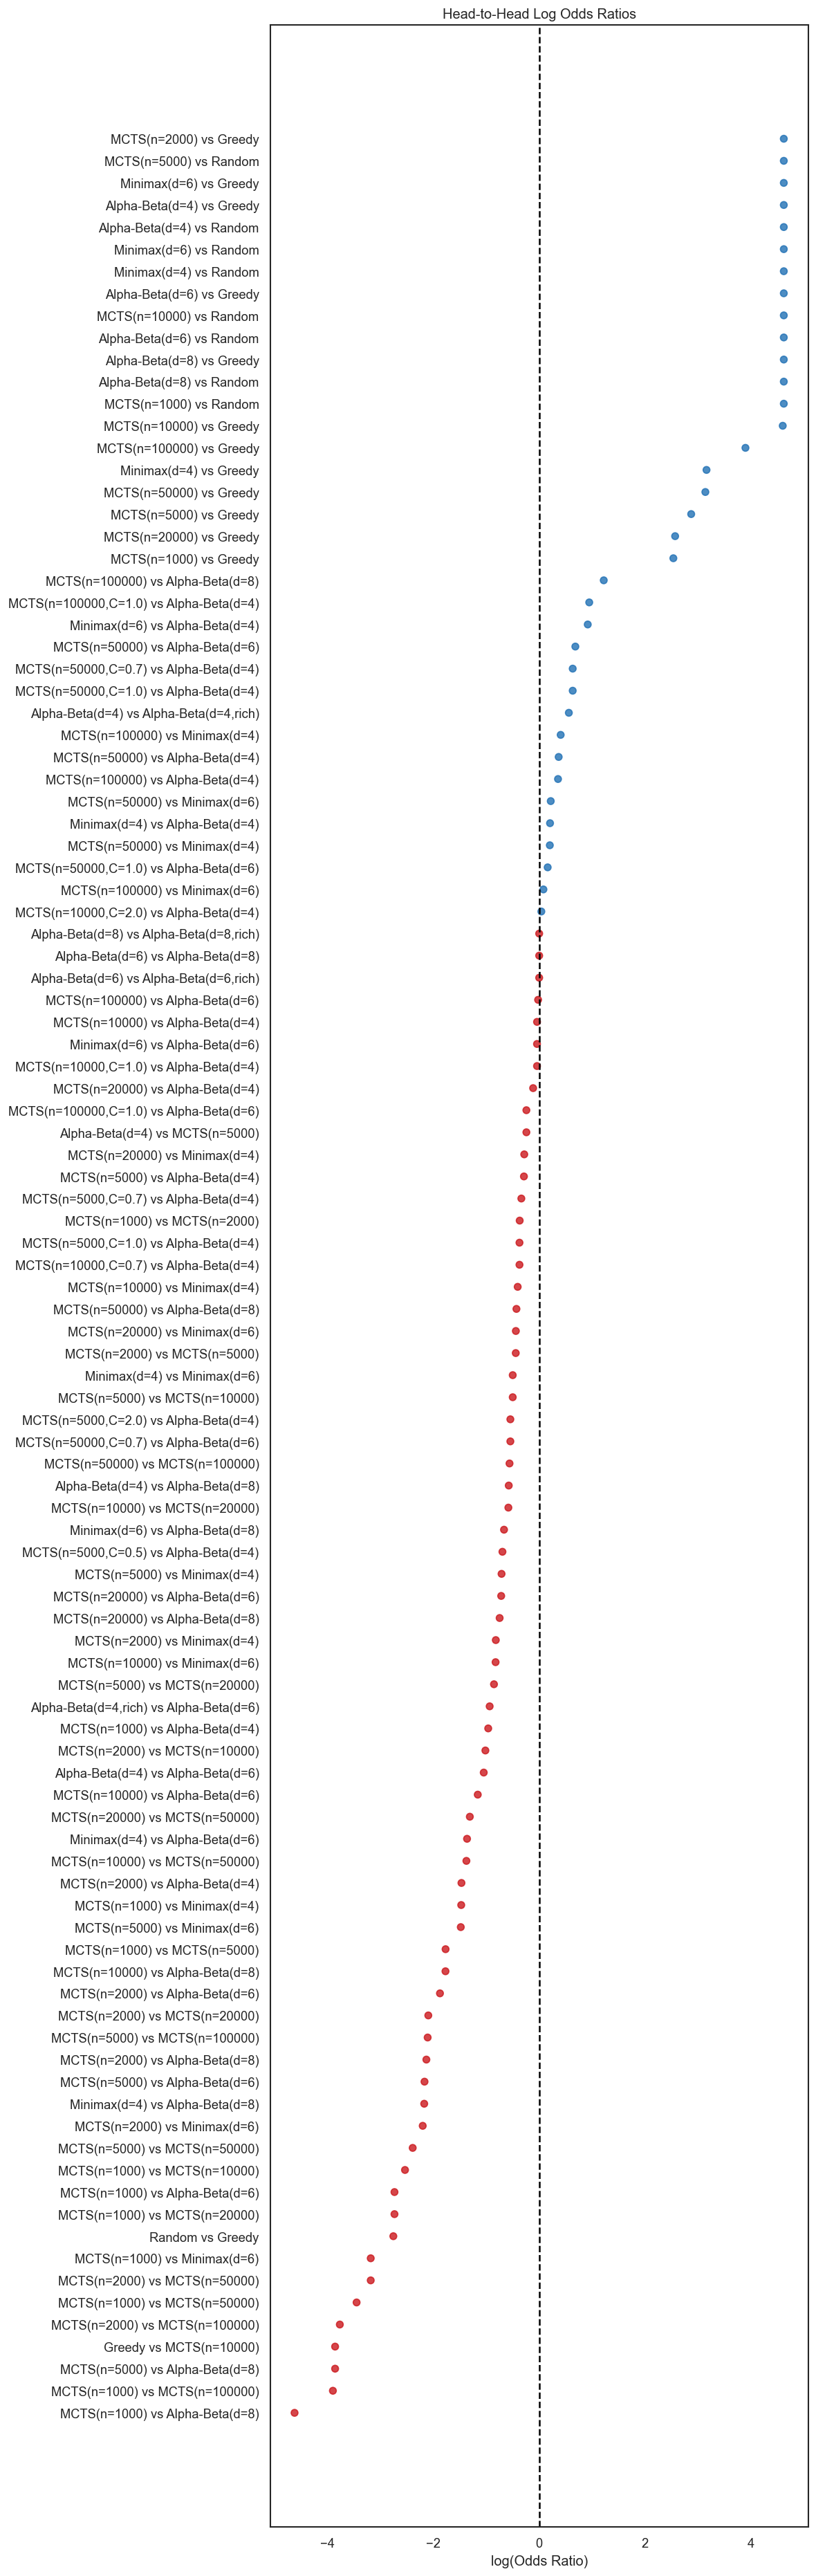

In [8]:
plot_df = matchup_df.dropna(subset=['odds_ratio']).copy()
plot_df = plot_df[plot_df['p1_label'] != plot_df['p2_label']].copy()
plot_df['log_or'] = np.log(plot_df['odds_ratio'])
plot_df = plot_df.sort_values('log_or').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, max(6, 0.3 * len(plot_df))))
y = np.arange(len(plot_df))

colors = ['#2171b5' if x > 0 else '#cb181d' for x in plot_df['log_or']]

ax.scatter(plot_df['log_or'], y, c=colors, s=35, alpha=0.8)
ax.axvline(0, linestyle='--', color='black')

ax.set_yticks(y)
ax.set_yticklabels(plot_df['matchup'])
ax.set_xlabel('log(Odds Ratio)')
ax.set_title('Head-to-Head Log Odds Ratios')
plt.tight_layout()
plt.show()

## 4. Agent Summary & Elo Ratings

In [9]:
# Compute Elo (10 shuffles, averaged)
np.random.seed(42)
elo_runs = [compute_elo(v2.sample(frac=1, random_state=i)) for i in range(10)]
all_agents = sorted(set(v2['p1_label']) | set(v2['p2_label']))
elo_avg = {a: np.mean([e.get(a, 1500) for e in elo_runs]) for a in all_agents}
elo_std = {a: np.std([e.get(a, 1500) for e in elo_runs]) for a in all_agents}

# Build agent summary
agent_rows = []
for agent in all_agents:
    as_p1 = v2[v2['p1_label'] == agent]
    as_p2 = v2[v2['p2_label'] == agent]
    total = len(as_p1) + len(as_p2)
    wins = (as_p1['winner'] == 'p1').sum() + (as_p2['winner'] == 'p2').sum()
    losses = (as_p1['winner'] == 'p2').sum() + (as_p2['winner'] == 'p1').sum()
    draws = (as_p1['winner'] == 'draw').sum() + (as_p2['winner'] == 'draw').sum()
    scores = list(as_p1['p1_score']) + list(as_p2['p2_score'])
    opp_scores = list(as_p1['p2_score']) + list(as_p2['p1_score'])
    times = list(as_p1['p1_avg_time_norm']) + list(as_p2['p2_avg_time_norm'])
    ets = list(as_p1['p1_extra_turns']) + list(as_p2['p2_extra_turns'])
    caps = list(as_p1['p1_captures']) + list(as_p2['p2_captures'])

    elo = elo_avg[agent]
    tier = 'S' if elo >= 1700 else 'A' if elo >= 1600 else 'B' if elo >= 1500 else 'C' if elo >= 1400 else 'D'

    agent_rows.append({
        'agent': agent, 'total': total, 'wins': wins, 'losses': losses, 'draws': draws,
        'win_rate': wins/total if total else 0,
        'chess_score': (wins + 0.5*draws)/total if total else 0,
        'avg_score': np.mean(scores), 'avg_margin': np.mean([a-b for a,b in zip(scores, opp_scores)]),
        'avg_ms': np.mean(times), 'avg_et': np.mean(ets), 'avg_cap': np.mean(caps),
        'elo': elo, 'elo_std': elo_std[agent], 'tier': tier,
    })

agent_df = pd.DataFrame(agent_rows).sort_values('elo', ascending=False).reset_index(drop=True)
agent_df.index = agent_df.index + 1  # 1-based rank
agent_df.index.name = 'Rank'

display_cols = ['agent','elo','elo_std','total','wins','losses','draws',
                'win_rate','chess_score','avg_score','avg_margin','avg_ms','tier']
agent_df[display_cols].style.format({
    'elo': '{:.0f}', 'elo_std': '{:.1f}', 'win_rate': '{:.1%}', 'chess_score': '{:.3f}',
    'avg_score': '{:.1f}', 'avg_margin': '{:+.1f}', 'avg_ms': '{:.3f}'
}).background_gradient(subset=['elo'], cmap='RdYlGn')


,agent,elo,elo_std,total,wins,losses,draws,win_rate,chess_score,avg_score,avg_margin,avg_ms,tier
Rank,,,,,,,,,,,,,
1,MCTS(n=100000),1732,34.6,996,600,319,77,60.2%,0.641,25.1,+2.2,12.237,S
2,Alpha-Beta(d=8),1730,27.5,1550,928,412,210,59.9%,0.666,27.5,+6.9,0.563,S
3,"MCTS(n=50000,C=1.0)",1703,38.1,100,59,40,1,59.0%,0.595,23.2,-1.5,2.573,S
4,Alpha-Beta(d=6),1696,60.0,1800,1103,622,75,61.3%,0.634,27.1,+6.3,0.065,A
5,"Alpha-Beta(d=8,rich)",1694,23.8,50,25,25,0,50.0%,0.500,24.9,+1.8,1.599,A
6,MCTS(n=50000),1689,42.9,1350,855,425,70,63.3%,0.659,25.5,+3.0,5.940,A
7,"MCTS(n=100000,C=1.0)",1673,32.3,100,58,42,0,58.0%,0.580,24.2,+0.5,11.457,A
8,Minimax(d=6),1652,35.7,850,566,258,26,66.6%,0.681,28.1,+8.1,1.076,A
9,"Alpha-Beta(d=6,rich)",1649,31.2,50,25,25,0,50.0%,0.500,28.3,+8.5,0.208,A


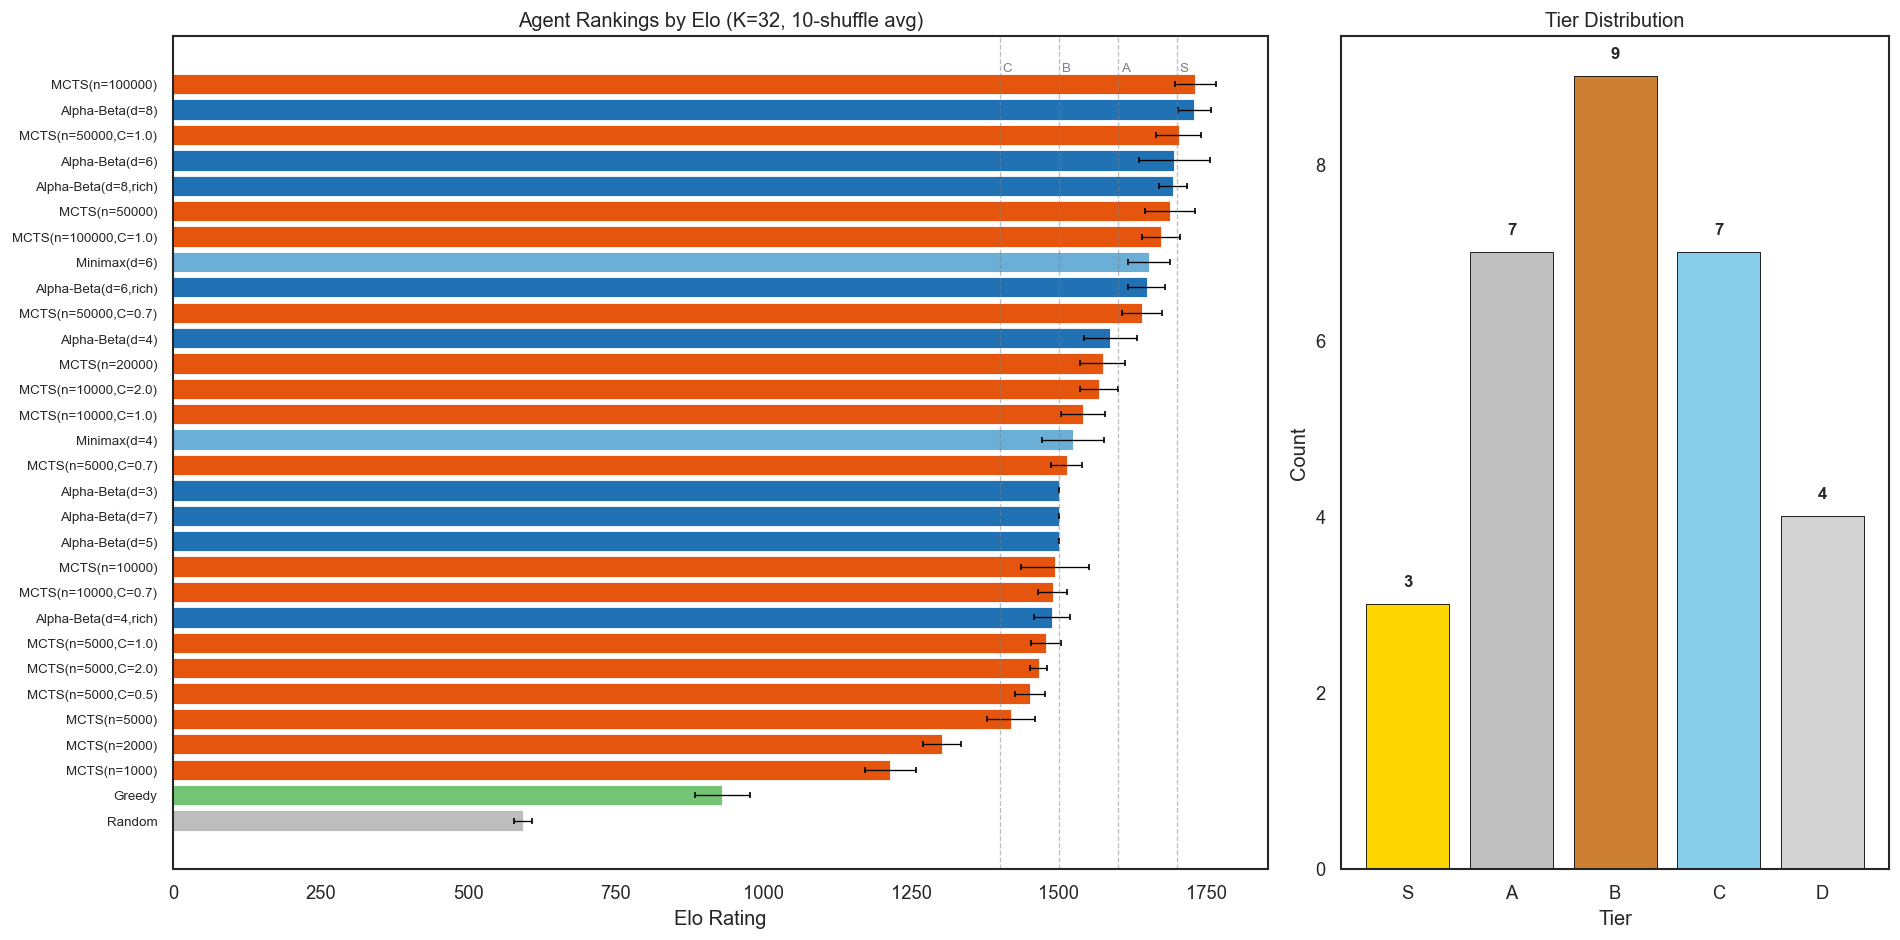

In [10]:
# Elo rating visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={'width_ratios': [2, 1]})

# Bar chart
ax = axes[0]
colors = [agent_color(a) for a in agent_df['agent']]
bars = ax.barh(range(len(agent_df)), agent_df['elo'], color=colors, edgecolor='white', linewidth=0.5)
ax.errorbar(agent_df['elo'].values, range(len(agent_df)), xerr=agent_df['elo_std'].values,
            fmt='none', color='black', capsize=2, linewidth=0.8)
ax.set_yticks(range(len(agent_df)))
ax.set_yticklabels(agent_df['agent'], fontsize=8)
ax.set_xlabel('Elo Rating')
ax.set_title('Agent Rankings by Elo (K=32, 10-shuffle avg)')
ax.invert_yaxis()

# Tier boundaries
for elo_thresh, label in [(1700, 'S'), (1600, 'A'), (1500, 'B'), (1400, 'C')]:
    ax.axvline(elo_thresh, color='gray', linestyle='--', alpha=0.5, linewidth=0.8)
    ax.text(elo_thresh+5, -0.5, label, fontsize=8, color='gray')

# Tier distribution
ax2 = axes[1]
tier_counts = agent_df['tier'].value_counts().reindex(['S','A','B','C','D'], fill_value=0)
tier_colors = {'S': '#FFD700', 'A': '#C0C0C0', 'B': '#CD7F32', 'C': '#87CEEB', 'D': '#D3D3D3'}
ax2.bar(tier_counts.index, tier_counts.values, color=[tier_colors[t] for t in tier_counts.index],
        edgecolor='black', linewidth=0.5)
ax2.set_xlabel('Tier'); ax2.set_ylabel('Count'); ax2.set_title('Tier Distribution')
for i, v in enumerate(tier_counts.values):
    ax2.text(i, v + 0.2, str(v), ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


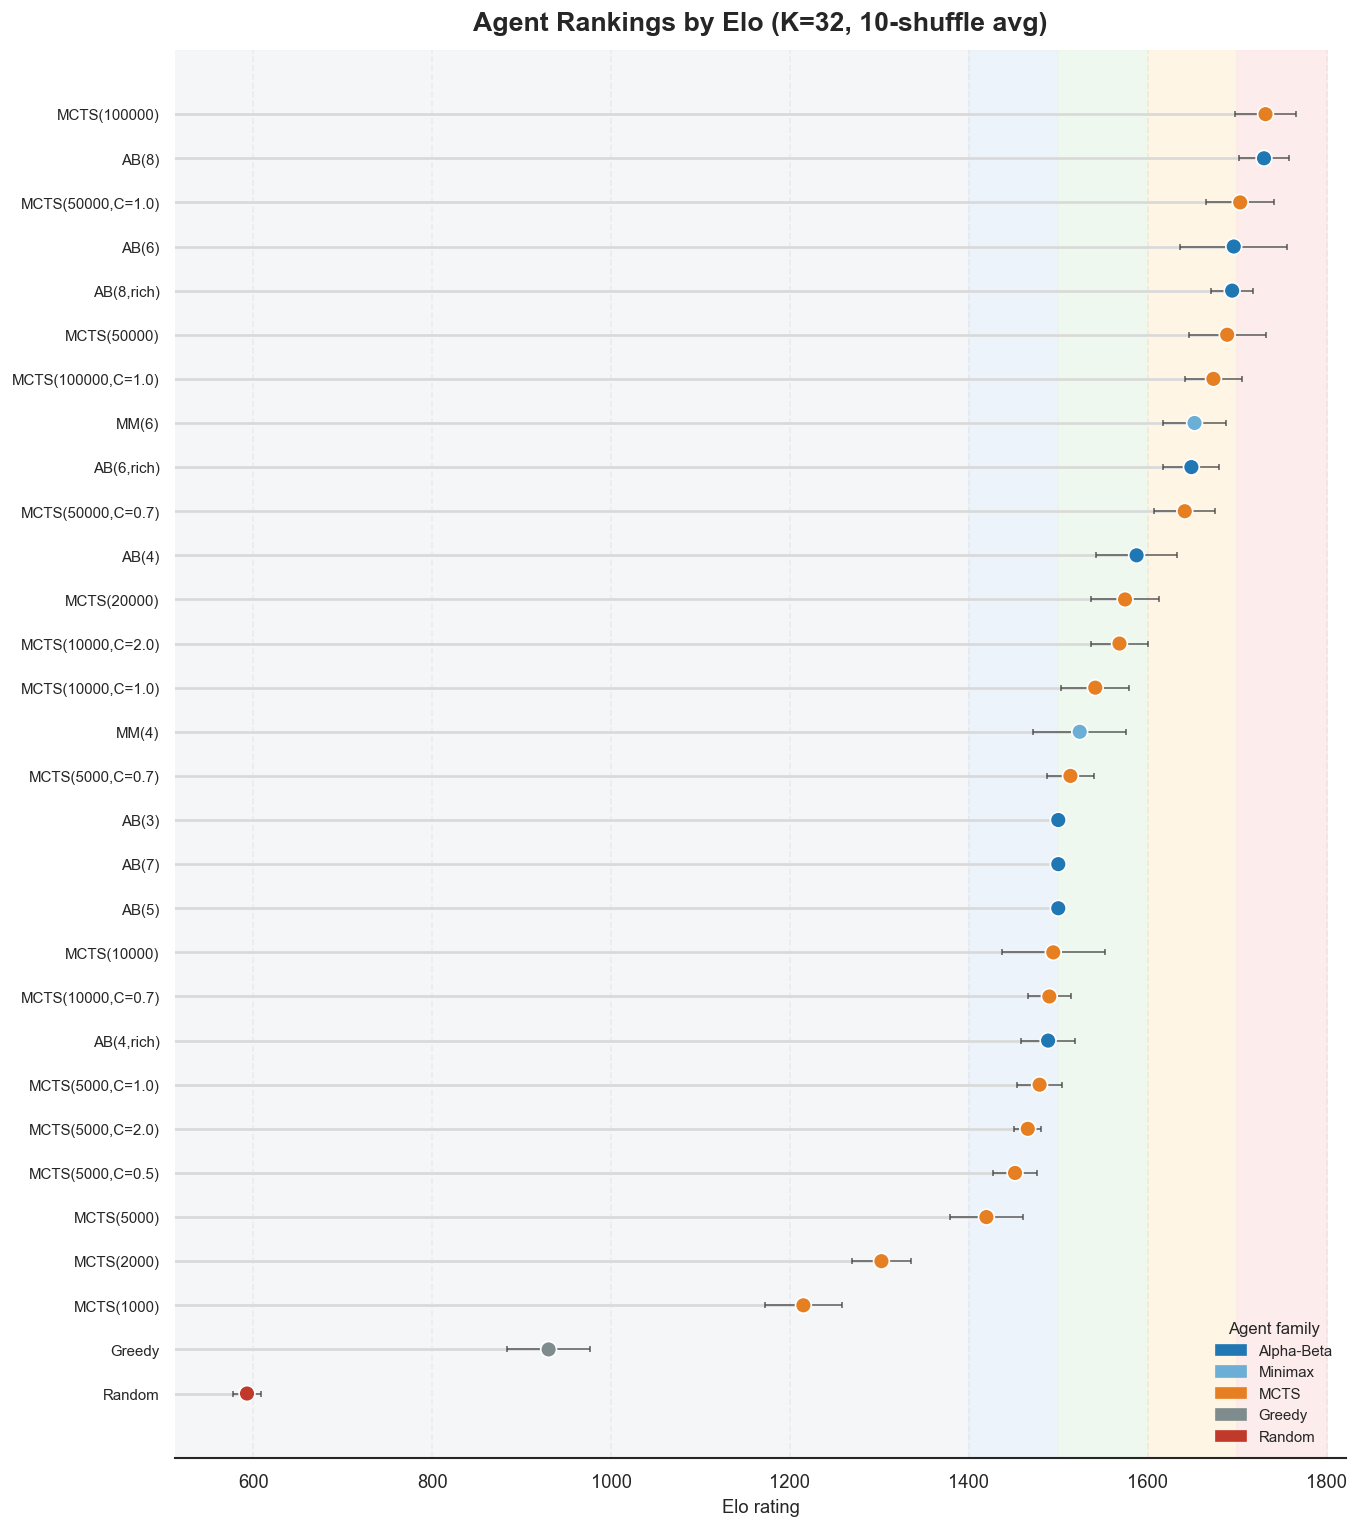

In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

def family_name(agent):
    if 'Alpha-Beta' in agent:
        return 'Alpha-Beta'
    if 'Minimax' in agent:
        return 'Minimax'
    if 'MCTS' in agent:
        return 'MCTS'
    if 'Greedy' in agent:
        return 'Greedy'
    if 'Random' in agent:
        return 'Random'
    return 'Other'

def agent_color(agent):
    palette = {
        'Alpha-Beta': '#1f77b4',
        'Minimax': '#6baed6',
        'MCTS': '#e67e22',
        'Greedy': '#7f8c8d',
        'Random': '#c0392b',
        'Other': '#999999'
    }
    return palette[family_name(agent)]

def short_label(agent):
    return (
        agent.replace('Alpha-Beta', 'AB')
             .replace('Minimax', 'MM')
             .replace('(n=', '(')
             .replace('(d=', '(')
    )

plot_df = agent_df.copy().sort_values('elo', ascending=True).reset_index(drop=True)
plot_df['family'] = plot_df['agent'].apply(family_name)
plot_df['color'] = plot_df['agent'].apply(agent_color)
plot_df['label'] = plot_df['agent'].apply(short_label)

fig_h = max(8, 0.38 * len(plot_df) + 1.5)
fig, ax = plt.subplots(figsize=(11.5, fig_h))

# Background tier bands
bands = [
    (0, 1400, '#f3f4f6'),
    (1400, 1500, '#e8f1fb'),
    (1500, 1600, '#eaf7ea'),
    (1600, 1700, '#fff3df'),
    (1700, 1800, '#fde8e8')
]
for x0, x1, color in bands:
    ax.axvspan(x0, x1, color=color, alpha=0.8, zorder=0)

y = np.arange(len(plot_df))

# Lollipop stems
for yi, elo in zip(y, plot_df['elo']):
    ax.hlines(yi, xmin=0, xmax=elo, color='#d9d9d9', lw=1.6, zorder=1)

# Error bars if available
if 'elo_std' in plot_df.columns:
    ax.errorbar(
        plot_df['elo'], y, xerr=plot_df['elo_std'],
        fmt='none', ecolor='#444444', elinewidth=1, capsize=2, alpha=0.8, zorder=2
    )

# Points
ax.scatter(
    plot_df['elo'], y,
    s=90,
    c=plot_df['color'],
    edgecolor='white',
    linewidth=1.0,
    zorder=3
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df['label'], fontsize=9)

ax.set_title('Agent Rankings by Elo (K=32, 10-shuffle avg)', fontsize=16, pad=12, fontweight='bold')
ax.set_xlabel('Elo rating', fontsize=11)
ax.set_xlim(
    max(500, plot_df['elo'].min() - 80),
    plot_df['elo'].max() + 90
)
ax.grid(axis='x', linestyle='--', alpha=0.25)
ax.set_axisbelow(True)

for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)

legend_handles = [
    mpatches.Patch(color='#1f77b4', label='Alpha-Beta'),
    mpatches.Patch(color='#6baed6', label='Minimax'),
    mpatches.Patch(color='#e67e22', label='MCTS'),
    mpatches.Patch(color='#7f8c8d', label='Greedy'),
    mpatches.Patch(color='#c0392b', label='Random'),
]
ax.legend(
    handles=legend_handles,
    title='Agent family',
    loc='lower right',
    frameon=False,
    fontsize=9,
    title_fontsize=10
)

plt.tight_layout()
plt.show()


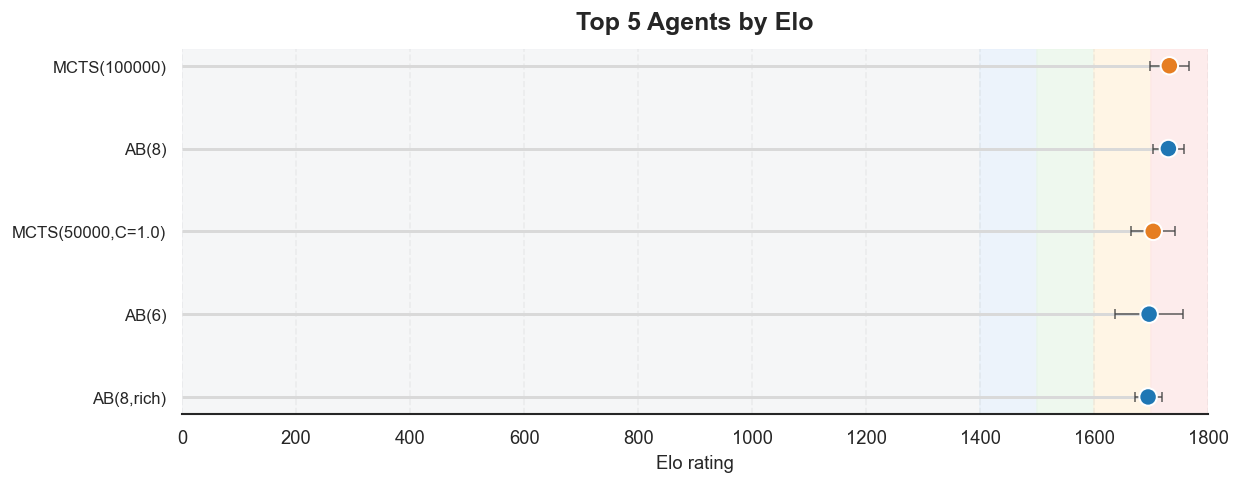

In [12]:
# Top 5 agents by Elo
top5_df = agent_df.copy().sort_values('elo', ascending=False).head(5).sort_values('elo', ascending=True).reset_index(drop=True)
top5_df['family'] = top5_df['agent'].apply(family_name)
top5_df['color'] = top5_df['agent'].apply(agent_color)
top5_df['label'] = top5_df['agent'].apply(short_label)

fig, ax = plt.subplots(figsize=(10.5, 4.2))

bands = [
    (0, 1400, '#f3f4f6'),
    (1400, 1500, '#e8f1fb'),
    (1500, 1600, '#eaf7ea'),
    (1600, 1700, '#fff3df'),
    (1700, 1800, '#fde8e8')
]
for x0, x1, color in bands:
    ax.axvspan(x0, x1, color=color, alpha=0.8, zorder=0)

y = np.arange(len(top5_df))

for yi, elo in zip(y, top5_df['elo']):
    ax.hlines(yi, xmin=0, xmax=elo, color='#d9d9d9', lw=1.8, zorder=1)

if 'elo_std' in top5_df.columns:
    ax.errorbar(
        top5_df['elo'], y, xerr=top5_df['elo_std'],
        fmt='none', ecolor='#444444', elinewidth=1, capsize=3, alpha=0.8, zorder=2
    )

ax.scatter(
    top5_df['elo'], y,
    s=110,
    c=top5_df['color'],
    edgecolor='white',
    linewidth=1.2,
    zorder=3
)

ax.set_yticks(y)
ax.set_yticklabels(top5_df['label'], fontsize=10)
ax.set_title('Top 5 Agents by Elo', fontsize=15, pad=12, fontweight='bold')
ax.set_xlabel('Elo rating', fontsize=11)
ax.set_xlim(0, 1800)
ax.grid(axis='x', linestyle='--', alpha=0.25)
ax.set_axisbelow(True)

for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

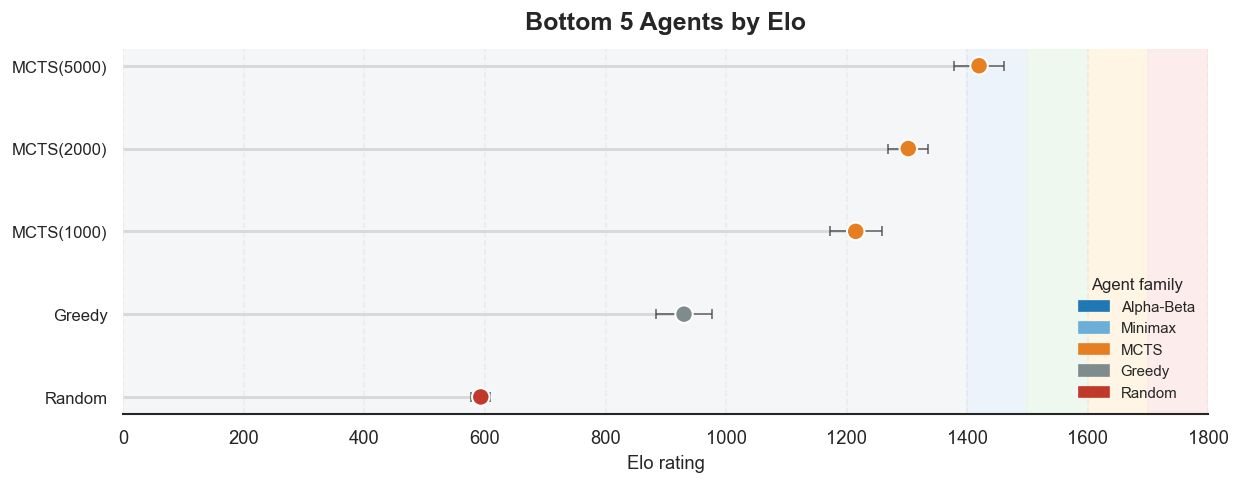

In [13]:
# Bottom 5 agents by Elo
bottom5_df = agent_df.copy().sort_values('elo', ascending=True).head(5).reset_index(drop=True)
bottom5_df['family'] = bottom5_df['agent'].apply(family_name)
bottom5_df['color'] = bottom5_df['agent'].apply(agent_color)
bottom5_df['label'] = bottom5_df['agent'].apply(short_label)

fig, ax = plt.subplots(figsize=(10.5, 4.2))

bands = [
    (0, 1400, '#f3f4f6'),
    (1400, 1500, '#e8f1fb'),
    (1500, 1600, '#eaf7ea'),
    (1600, 1700, '#fff3df'),
    (1700, 1800, '#fde8e8')
]
for x0, x1, color in bands:
    ax.axvspan(x0, x1, color=color, alpha=0.8, zorder=0)

y = np.arange(len(bottom5_df))

for yi, elo in zip(y, bottom5_df['elo']):
    ax.hlines(yi, xmin=0, xmax=elo, color='#d9d9d9', lw=1.8, zorder=1)

if 'elo_std' in bottom5_df.columns:
    ax.errorbar(
        bottom5_df['elo'], y, xerr=bottom5_df['elo_std'],
        fmt='none', ecolor='#444444', elinewidth=1, capsize=3, alpha=0.8, zorder=2
    )

ax.scatter(
    bottom5_df['elo'], y,
    s=110,
    c=bottom5_df['color'],
    edgecolor='white',
    linewidth=1.2,
    zorder=3
)

ax.set_yticks(y)
ax.set_yticklabels(bottom5_df['label'], fontsize=10)
ax.set_title('Bottom 5 Agents by Elo', fontsize=15, pad=12, fontweight='bold')
ax.set_xlabel('Elo rating', fontsize=11)
ax.set_xlim(0, 1800)
ax.grid(axis='x', linestyle='--', alpha=0.25)
ax.set_axisbelow(True)

for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)


legend_handles = [
    mpatches.Patch(color='#1f77b4', label='Alpha-Beta'),
    mpatches.Patch(color='#6baed6', label='Minimax'),
    mpatches.Patch(color='#e67e22', label='MCTS'),
    mpatches.Patch(color='#7f8c8d', label='Greedy'),
    mpatches.Patch(color='#c0392b', label='Random'),
]
ax.legend(
    handles=legend_handles,
    title='Agent family',
    loc='lower right',
    frameon=False,
    fontsize=9,
    title_fontsize=10
)

plt.tight_layout()
plt.show()


## 5. MCTS Scaling Analysis

In [14]:
mcts_agents = ['MCTS(n=1000)','MCTS(n=2000)','MCTS(n=5000)',
               'MCTS(n=10000)','MCTS(n=20000)','MCTS(n=50000)','MCTS(n=100000)']
opponents = ['Greedy','Minimax(d=4)','Minimax(d=6)',
             'Alpha-Beta(d=4)','Alpha-Beta(d=6)','Alpha-Beta(d=8)']
n_values = [1000, 2000, 5000, 10000, 20000, 50000, 100000]

# Build scaling table
scale_data = {}
for mcts, n_val in zip(mcts_agents, n_values):
    row = {}
    for opp in opponents:
        res = pairwise_result(v2, mcts, opp)
        if res:
            row[opp] = {'wr': res['a_wr'], 'n': res['n'],
                        'ci_lo': res['a_ci'][1], 'ci_hi': res['a_ci'][2]}
        else:
            row[opp] = None
    scale_data[n_val] = row

# Display table
print("MCTS Win Rate by Simulation Budget and Opponent")
print("=" * 90)
header = f"{'Budget':>10s}"
for opp in opponents:
    short = opp.replace('Alpha-Beta','AB').replace('Minimax','MM')
    header += f"  {short:>12s}"
print(header)
print("-" * 90)
for n_val in n_values:
    line = f"{n_val:>10,d}"
    for opp in opponents:
        d = scale_data[n_val].get(opp)
        if d:
            line += f"  {d['wr']:>5.0%} (n={d['n']:>3d})"
        else:
            line += f"  {'---':>12s}"
    print(line)


MCTS Win Rate by Simulation Budget and Opponent
    Budget        Greedy       MM(d=4)       MM(d=6)       AB(d=4)       AB(d=6)       AB(d=8)
------------------------------------------------------------------------------------------
     1,000    88% (n=100)    17% (n=100)     4% (n= 50)    26% (n= 50)     6% (n= 50)     0% (n= 50)
     2,000   100% (n= 50)    30% (n= 50)    10% (n= 50)    18% (n= 50)    12% (n= 50)    10% (n= 50)
     5,000    88% (n=100)    30% (n=100)    18% (n=100)    49% (n=100)    10% (n=100)     2% (n= 50)
    10,000    96% (n=100)    38% (n=100)    29% (n=100)    49% (n=150)    22% (n=200)    14% (n=200)
    20,000    91% (n=100)    40% (n=100)    38% (n=100)    46% (n=200)    28% (n=150)    31% (n=150)
    50,000    92% (n= 50)    55% (n=100)    51% (n=100)    58% (n=200)    62% (n=150)    37% (n=150)
   100,000    98% (n= 50)    60% (n= 50)    52% (n= 50)    58% (n=200)    50% (n=200)    47% (n=150)


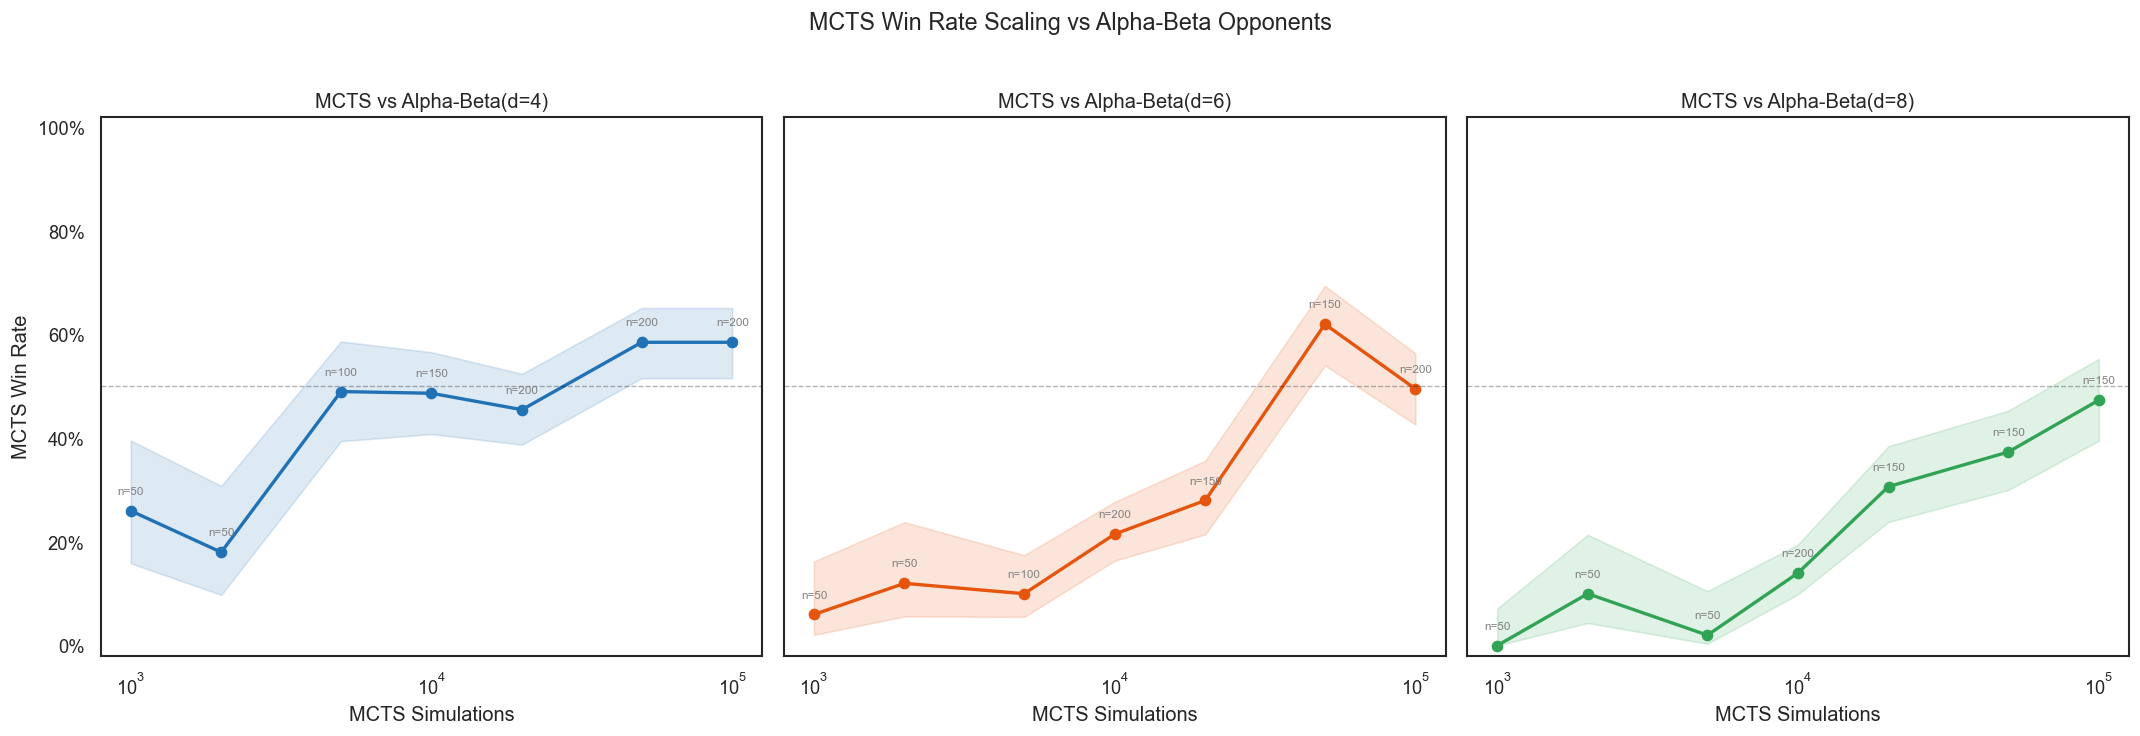

In [15]:
# MCTS scaling line chart
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
ab_opps = [('Alpha-Beta(d=4)', '#2171b5'), ('Alpha-Beta(d=6)', '#e6550d'), ('Alpha-Beta(d=8)', '#31a354')]

for idx, (opp, color) in enumerate(ab_opps):
    ax = axes[idx]
    wrs, ns, ci_los, ci_his, x_vals = [], [], [], [], []
    for n_val in n_values:
        d = scale_data[n_val].get(opp)
        if d:
            wrs.append(d['wr']); ns.append(d['n'])
            ci_los.append(d['ci_lo']); ci_his.append(d['ci_hi'])
            x_vals.append(n_val)

    ax.plot(x_vals, wrs, 'o-', color=color, linewidth=2, markersize=6)
    ax.fill_between(x_vals, ci_los, ci_his, alpha=0.15, color=color)

    # Annotate sample sizes
    for x, wr, n in zip(x_vals, wrs, ns):
        ax.annotate(f'n={n}', (x, wr), textcoords='offset points',
                    xytext=(0, 10), fontsize=7, ha='center', color='gray')

    ax.axhline(0.5, color='black', linestyle='--', alpha=0.3, linewidth=0.8)
    ax.set_xscale('log')
    ax.set_xlabel('MCTS Simulations')
    ax.set_title(f'MCTS vs {opp}')
    ax.set_ylim(-0.02, 1.02)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

axes[0].set_ylabel('MCTS Win Rate')
plt.suptitle('MCTS Win Rate Scaling vs Alpha-Beta Opponents', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


## 6. Exploration Constant (C) Sensitivity

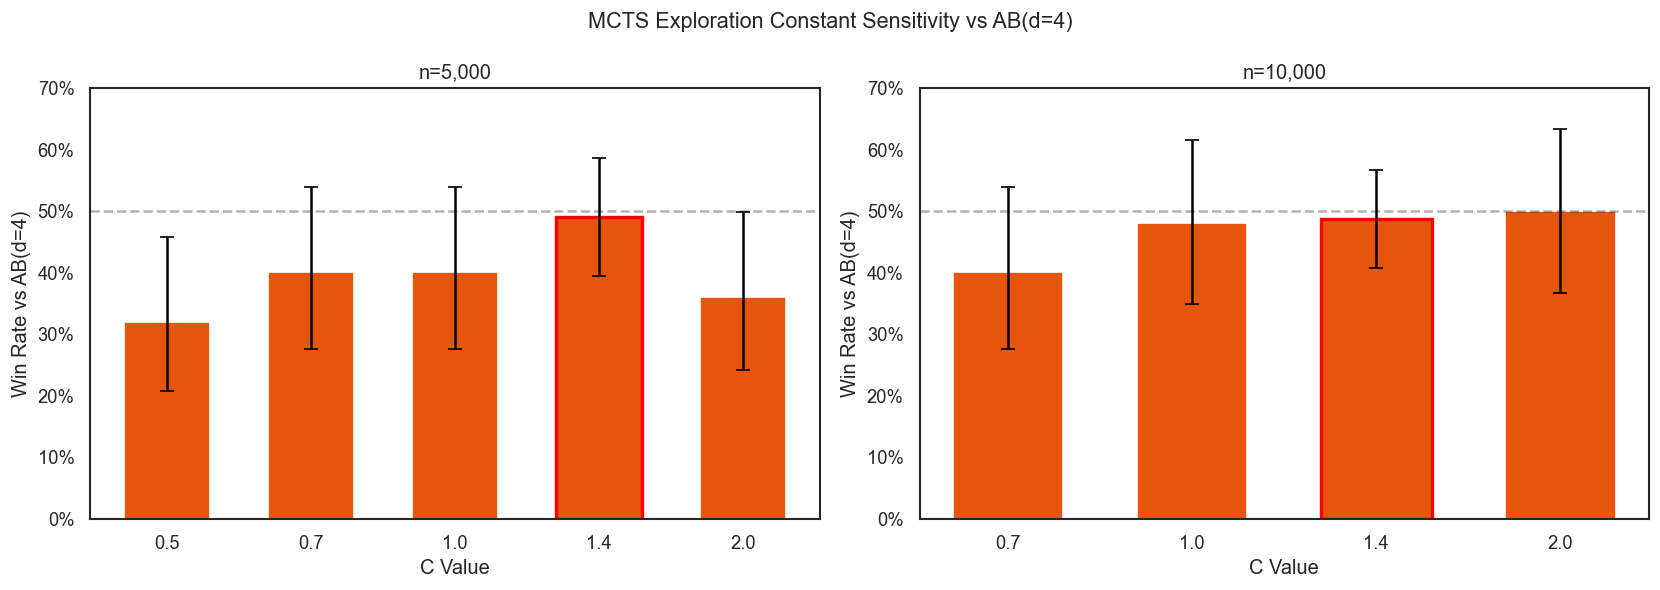

              agent   c       wr    ci_lo    ci_hi  n_games
 MCTS(n=5000,C=0.5) 0.5 0.320000 0.207580 0.458106       50
 MCTS(n=5000,C=0.7) 0.7 0.400000 0.276082 0.538188       50
 MCTS(n=5000,C=1.0) 1.0 0.400000 0.276082 0.538188       50
       MCTS(n=5000) 1.4 0.490000 0.394218 0.586522      100
 MCTS(n=5000,C=2.0) 2.0 0.360000 0.241386 0.498592       50
MCTS(n=10000,C=0.7) 0.7 0.400000 0.276082 0.538188       50
MCTS(n=10000,C=1.0) 1.0 0.480000 0.347969 0.614885       50
      MCTS(n=10000) 1.4 0.486667 0.408016 0.565984      150
MCTS(n=10000,C=2.0) 2.0 0.500000 0.366443 0.633557       50


In [16]:
c_configs = [
    ('MCTS(n=5000,C=0.5)', 5000, 0.5), ('MCTS(n=5000,C=0.7)', 5000, 0.7),
    ('MCTS(n=5000,C=1.0)', 5000, 1.0), ('MCTS(n=5000)', 5000, 1.4),
    ('MCTS(n=5000,C=2.0)', 5000, 2.0),
    ('MCTS(n=10000,C=0.7)', 10000, 0.7), ('MCTS(n=10000,C=1.0)', 10000, 1.0),
    ('MCTS(n=10000)', 10000, 1.4), ('MCTS(n=10000,C=2.0)', 10000, 2.0),
]
opp = 'Alpha-Beta(d=4)'

c_rows = []
for agent, n_sims, c_val in c_configs:
    res = pairwise_result(v2, agent, opp)
    if res:
        c_rows.append({'agent': agent, 'n_sims': n_sims, 'c': c_val,
                        'wr': res['a_wr'], 'ci_lo': res['a_ci'][1], 'ci_hi': res['a_ci'][2],
                        'n_games': res['n']})
c_df = pd.DataFrame(c_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, n_sims in zip(axes, [5000, 10000]):
    sub = c_df[c_df['n_sims'] == n_sims]
    ax.bar(sub['c'].astype(str), sub['wr'], color='#e6550d', edgecolor='white', width=0.6)
    ax.errorbar(range(len(sub)), sub['wr'],
                yerr=[sub['wr']-sub['ci_lo'], sub['ci_hi']-sub['wr']],
                fmt='none', color='black', capsize=4)
    ax.axhline(0.5, color='black', linestyle='--', alpha=0.3)
    ax.set_xlabel('C Value'); ax.set_ylabel('Win Rate vs AB(d=4)')
    ax.set_title(f'n={n_sims:,}'); ax.set_ylim(0, 0.7)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    # Highlight default
    for i, row in sub.iterrows():
        if row['c'] == 1.4:
            ax.get_children()[list(sub.index).index(i)].set_edgecolor('red')
            ax.get_children()[list(sub.index).index(i)].set_linewidth(2)
plt.suptitle('MCTS Exploration Constant Sensitivity vs AB(d=4)', fontsize=13)
plt.tight_layout(); plt.show()
print(c_df[['agent','c','wr','ci_lo','ci_hi','n_games']].to_string(index=False))


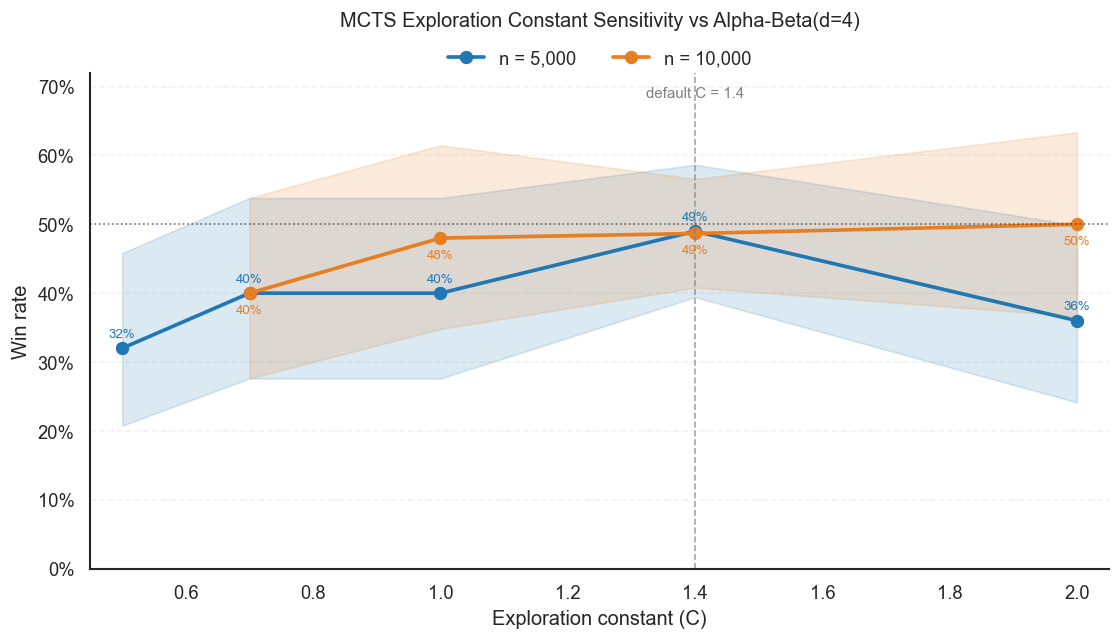

In [17]:
c_configs = [
    ('MCTS(n=5000,C=0.5)', 5000, 0.5),
    ('MCTS(n=5000,C=0.7)', 5000, 0.7),
    ('MCTS(n=5000,C=1.0)', 5000, 1.0),
    ('MCTS(n=5000)', 5000, 1.4),
    ('MCTS(n=5000,C=2.0)', 5000, 2.0),
    ('MCTS(n=10000,C=0.7)', 10000, 0.7),
    ('MCTS(n=10000,C=1.0)', 10000, 1.0),
    ('MCTS(n=10000)', 10000, 1.4),
    ('MCTS(n=10000,C=2.0)', 10000, 2.0),
]

opp = 'Alpha-Beta(d=4)'

c_rows = []
for agent, n_sims, c_val in c_configs:
    res = pairwise_result(v2, agent, opp)
    if res:
        c_rows.append({
            'agent': agent,
            'n_sims': n_sims,
            'c': c_val,
            'wr': res['a_wr'],
            'ci_lo': res['a_ci'][1],
            'ci_hi': res['a_ci'][2],
            'n_games': res['n']
        })

c_df = pd.DataFrame(c_rows).sort_values(['n_sims', 'c'])

fig, ax = plt.subplots(figsize=(9.5, 5.5))

colors = {
    5000: '#1f77b4',
    10000: '#e67e22'
}

label_offsets = {
    5000: 0.012,
    10000: -0.016
}

for n_sims in sorted(c_df['n_sims'].unique()):
    sub = c_df[c_df['n_sims'] == n_sims].sort_values('c')

    ax.fill_between(
        sub['c'],
        sub['ci_lo'],
        sub['ci_hi'],
        color=colors[n_sims],
        alpha=0.16
    )

    ax.plot(
        sub['c'],
        sub['wr'],
        marker='o',
        markersize=7,
        linewidth=2.2,
        color=colors[n_sims],
        label=f'n = {n_sims:,}'
    )

    for _, row in sub.iterrows():
        offset = label_offsets[n_sims]
        va = 'bottom' if offset > 0 else 'top'
        ax.text(
            row['c'],
            row['wr'] + offset,
            f"{row['wr']:.0%}",
            ha='center',
            va=va,
            fontsize=8,
            color=colors[n_sims]
        )

ax.axvline(1.4, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax.text(1.4, 0.68, 'default C = 1.4', ha='center', va='bottom', fontsize=9, color='gray')

ax.axhline(0.5, color='black', linestyle=':', linewidth=1, alpha=0.5)

ax.set_title('MCTS Exploration Constant Sensitivity vs Alpha-Beta(d=4)', pad=28)
ax.set_xlabel('Exploration constant (C)')
ax.set_ylabel('Win rate')
ax.set_ylim(0, 0.72)
ax.set_xlim(0.45, 2.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.grid(axis='y', linestyle='--', alpha=0.25)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

ax.legend(
    frameon=False,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.08),
    ncol=2
)

plt.tight_layout()
plt.show()


## 7. Evaluation Function: Standard vs. Rich

Depth 4: Standard 28-16-6 Rich (n=50)
Depth 6: Standard 25-25-0 Rich (n=50)
Depth 8: Standard 25-25-0 Rich (n=50)

Knowledge vs Search: rich(d=4) 11-28-11 std(d=6)


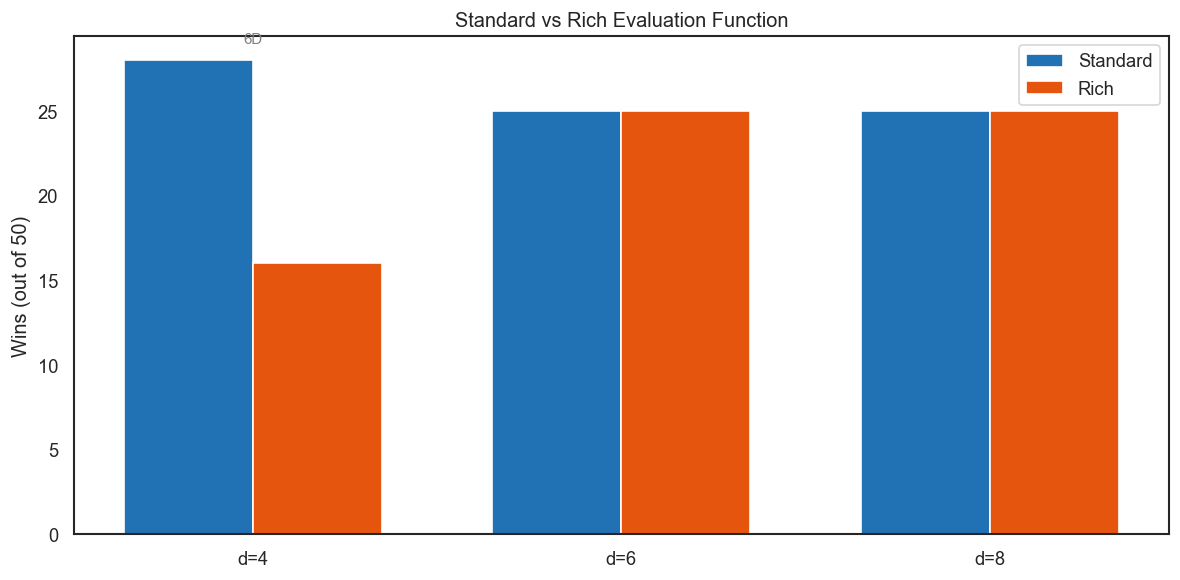

In [18]:
eval_pairs = [
    ('Alpha-Beta(d=4)', 'Alpha-Beta(d=4,rich)', 4),
    ('Alpha-Beta(d=6)', 'Alpha-Beta(d=6,rich)', 6),
    ('Alpha-Beta(d=8)', 'Alpha-Beta(d=8,rich)', 8),
]

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(eval_pairs))
width = 0.35

for idx, (std, rich, depth) in enumerate(eval_pairs):
    res = pairwise_result(v2, std, rich)
    print(f"Depth {depth}: Standard {res['a_wins']}-{res['b_wins']}-{res['draws']} Rich (n={res['n']})")
    ax.bar(idx - width/2, res['a_wins'], width, color='#2171b5', label='Standard' if idx==0 else '')
    ax.bar(idx + width/2, res['b_wins'], width, color='#e6550d', label='Rich' if idx==0 else '')
    if res['draws'] > 0:
        ax.text(idx, max(res['a_wins'], res['b_wins'])+1, f"{res['draws']}D",
                ha='center', fontsize=9, color='gray')

# Knowledge vs search
res_kvs = pairwise_result(v2, 'Alpha-Beta(d=4,rich)', 'Alpha-Beta(d=6)')
print(f"\nKnowledge vs Search: rich(d=4) {res_kvs['a_wins']}-{res_kvs['b_wins']}-{res_kvs['draws']} std(d=6)")

ax.set_xticks(x); ax.set_xticklabels([f'd={d}' for _,_,d in eval_pairs])
ax.set_ylabel('Wins (out of 50)'); ax.set_title('Standard vs Rich Evaluation Function')
ax.legend(); plt.tight_layout(); plt.show()


## 8. First-Mover Advantage in Self-Play

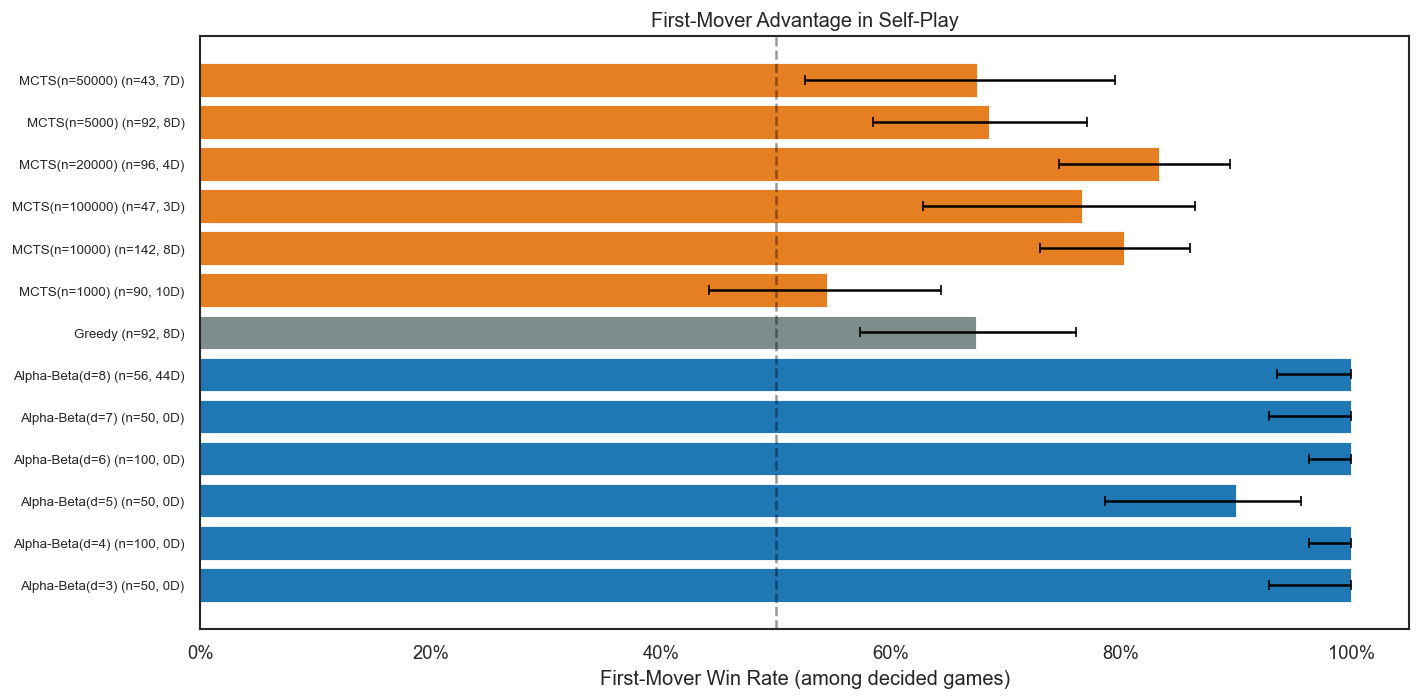

,agent,n,decided,draws,fm_wins,sm_wins,fm_rate,ci_lo,ci_hi
0,Alpha-Beta(d=3),50,50,0,50,0,1.000000,0.928650,1.000000
1,Alpha-Beta(d=4),100,100,0,100,0,1.000000,0.963005,1.000000
2,Alpha-Beta(d=5),50,50,0,45,5,0.900000,0.786395,0.956525
3,Alpha-Beta(d=6),100,100,0,100,0,1.000000,0.963005,1.000000
4,Alpha-Beta(d=7),50,50,0,50,0,1.000000,0.928650,1.000000
5,Alpha-Beta(d=8),100,56,44,56,0,1.000000,0.935804,1.000000
6,Greedy,100,92,8,62,30,0.673913,0.572831,0.761054
7,MCTS(n=1000),100,90,10,49,41,0.544444,0.441844,0.643406
8,MCTS(n=10000),150,142,8,114,28,0.802817,0.729776,0.859905
9,MCTS(n=100000),50,47,3,36,11,0.765957,0.627755,0.863969


In [19]:
self_play = v2[v2['p1_label'] == v2['p2_label']].copy()

fm_rows = []
for agent, grp in self_play.groupby('p1_label'):
    n = len(grp)
    decided = grp[grp['winner'] != 'draw']
    draws = n - len(decided)
    fm_w = (decided['first_mover_won'] == True).sum() if len(decided) > 0 else 0
    fm_n = len(decided)
    fm_rate, fm_lo, fm_hi = wilson_ci(fm_w, fm_n) if fm_n > 0 else (None, None, None)
    fm_rows.append({'agent': agent, 'n': n, 'decided': fm_n, 'draws': draws,
                    'fm_wins': fm_w, 'sm_wins': fm_n - fm_w,
                    'fm_rate': fm_rate, 'ci_lo': fm_lo, 'ci_hi': fm_hi})
fm_df = pd.DataFrame(fm_rows).sort_values('agent')

fig, ax = plt.subplots(figsize=(12, 6))
y = range(len(fm_df))
ax.barh(y, fm_df['fm_rate'].fillna(0), color=[agent_color(a) for a in fm_df['agent']],
        edgecolor='white', linewidth=0.5)
# Error bars
valid = fm_df['fm_rate'].notna()
lo_err = (fm_df.loc[valid, 'fm_rate'] - fm_df.loc[valid, 'ci_lo']).clip(lower=0)
hi_err = (fm_df.loc[valid, 'ci_hi'] - fm_df.loc[valid, 'fm_rate']).clip(lower=0)
ax.errorbar(fm_df.loc[valid, 'fm_rate'], [i for i, v in enumerate(valid) if v],
            xerr=[lo_err, hi_err], fmt='none', color='black', capsize=3)
ax.axvline(0.5, color='black', linestyle='--', alpha=0.4)
ax.set_yticks(y); ax.set_yticklabels([f"{r['agent']} (n={r['decided']}, {r['draws']}D)"
                                       for _, r in fm_df.iterrows()], fontsize=8)
ax.set_xlabel('First-Mover Win Rate (among decided games)')
ax.set_title('First-Mover Advantage in Self-Play')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout(); plt.show()

fm_df[['agent','n','decided','draws','fm_wins','sm_wins','fm_rate','ci_lo','ci_hi']]


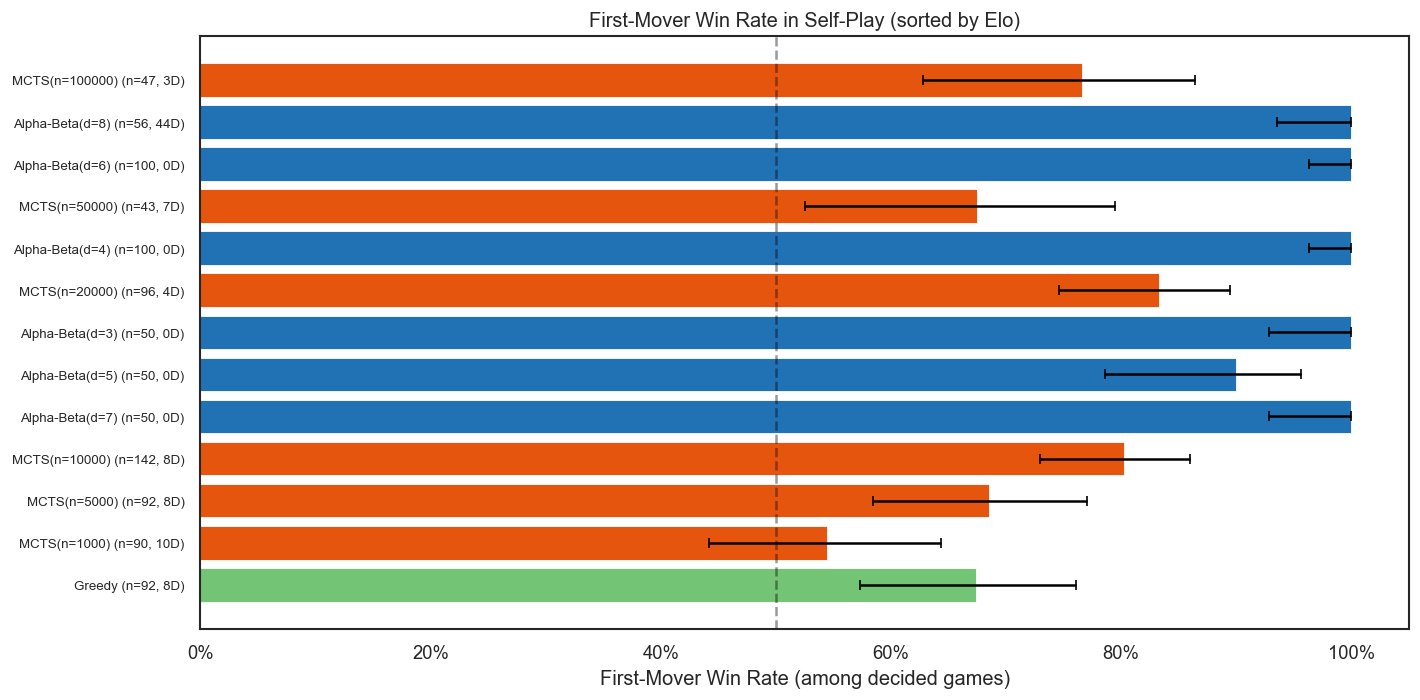

,agent,elo,n,decided,draws,fm_wins,sm_wins,fm_rate,ci_lo,ci_hi
0,MCTS(n=100000),1731.686013,50,47,3,36,11,0.765957,0.627755,0.863969
1,Alpha-Beta(d=8),1729.987578,100,56,44,56,0,1.000000,0.935804,1.000000
2,Alpha-Beta(d=6),1696.175213,100,100,0,100,0,1.000000,0.963005,1.000000
3,MCTS(n=50000),1688.837820,50,43,7,29,14,0.674419,0.525159,0.795069
4,Alpha-Beta(d=4),1587.547582,100,100,0,100,0,1.000000,0.963005,1.000000
5,MCTS(n=20000),1574.662307,100,96,4,80,16,0.833333,0.746288,0.894727
6,Alpha-Beta(d=3),1500.000000,50,50,0,50,0,1.000000,0.928650,1.000000
7,Alpha-Beta(d=5),1500.000000,50,50,0,45,5,0.900000,0.786395,0.956525
8,Alpha-Beta(d=7),1500.000000,50,50,0,50,0,1.000000,0.928650,1.000000
9,MCTS(n=10000),1494.407793,150,142,8,114,28,0.802817,0.729776,0.859905


In [20]:
def agent_color(agent):
    if 'Alpha-Beta' in agent: return '#2171b5'
    if 'Minimax' in agent: return '#6baed6'
    if 'MCTS' in agent: return '#e6550d'
    if 'Greedy' in agent: return '#74c476'
    if 'Random' in agent: return '#bdbdbd'
    return '#756bb1'

# First-mover self-play win rate, ordered by Elo
self_play = v2[v2['p1_label'] == v2['p2_label']].copy()

fm_rows = []
for agent, grp in self_play.groupby('p1_label'):
    n = len(grp)
    decided = grp[grp['winner'] != 'draw']
    draws = n - len(decided)
    fm_w = (decided['first_mover_won'] == True).sum() if len(decided) > 0 else 0
    fm_n = len(decided)
    fm_rate, fm_lo, fm_hi = wilson_ci(fm_w, fm_n) if fm_n > 0 else (None, None, None)

    fm_rows.append({
        'agent': agent,
        'n': n,
        'decided': fm_n,
        'draws': draws,
        'fm_wins': fm_w,
        'sm_wins': fm_n - fm_w,
        'fm_rate': fm_rate,
        'ci_lo': fm_lo,
        'ci_hi': fm_hi,
    })

fm_elo_df = (
    pd.DataFrame(fm_rows)
    .merge(agent_df[['agent', 'elo']], on='agent', how='left')
    .sort_values('elo', ascending=False)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(12, 6))
y = range(len(fm_elo_df))

bar_colors = [agent_color(a) for a in fm_elo_df['agent']]

ax.barh(
    y,
    fm_elo_df['fm_rate'].fillna(0),
    color=bar_colors,
    edgecolor='white',
    linewidth=0.5
)

valid = fm_elo_df['fm_rate'].notna()
valid_y = [i for i, v in enumerate(valid) if v]
lo_err = (fm_elo_df.loc[valid, 'fm_rate'] - fm_elo_df.loc[valid, 'ci_lo']).clip(lower=0)
hi_err = (fm_elo_df.loc[valid, 'ci_hi'] - fm_elo_df.loc[valid, 'fm_rate']).clip(lower=0)

ax.errorbar(
    fm_elo_df.loc[valid, 'fm_rate'],
    valid_y,
    xerr=[lo_err, hi_err],
    fmt='none',
    color='black',
    capsize=3
)

ax.axvline(0.5, color='black', linestyle='--', alpha=0.4)

ax.set_yticks(list(y))
ax.set_yticklabels(
    [f"{r['agent']} (n={r['decided']}, {r['draws']}D)" for _, r in fm_elo_df.iterrows()],
    fontsize=8
)
ax.invert_yaxis()

ax.set_xlabel('First-Mover Win Rate (among decided games)')
ax.set_title('First-Mover Win Rate in Self-Play (sorted by Elo)')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))

plt.tight_layout()
plt.show()

fm_elo_df[['agent', 'elo', 'n', 'decided', 'draws', 'fm_wins', 'sm_wins', 'fm_rate', 'ci_lo', 'ci_hi']]


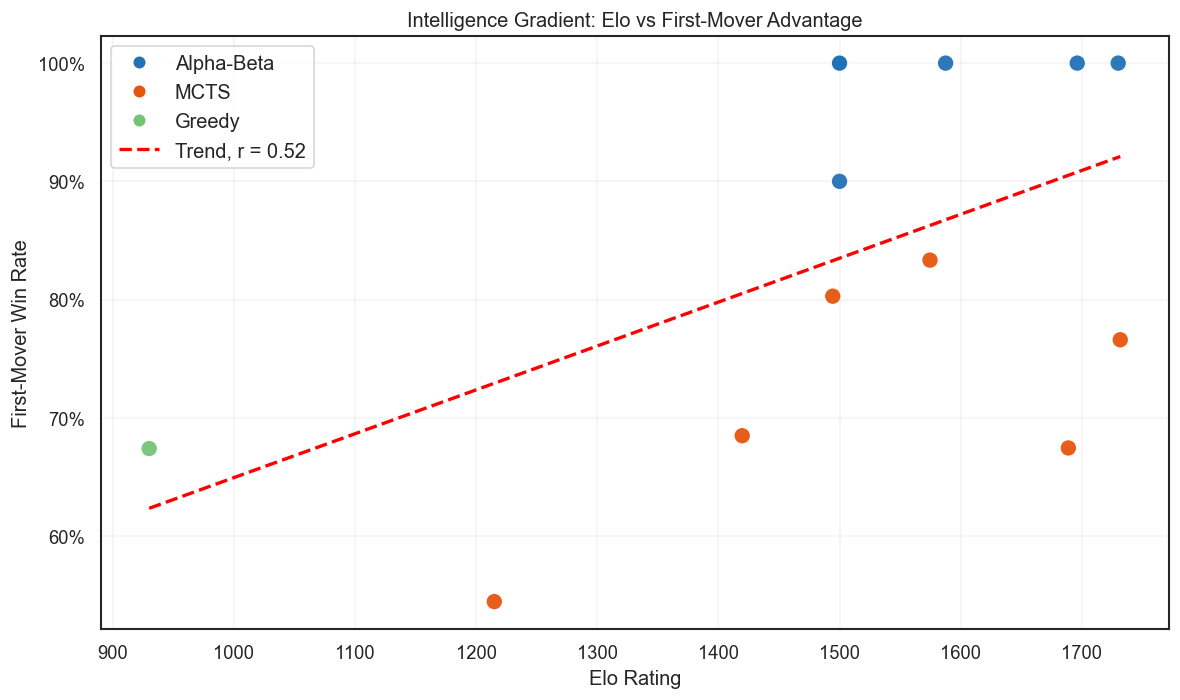

,agent,elo,decided,draws,fm_rate,ci_lo,ci_hi,tier
0,Greedy,930.198658,92,8,0.673913,0.572831,0.761054,D
1,MCTS(n=1000),1215.048226,90,10,0.544444,0.441844,0.643406,D
2,MCTS(n=5000),1419.672312,92,8,0.684783,0.584065,0.770687,C
3,MCTS(n=10000),1494.407793,142,8,0.802817,0.729776,0.859905,C
4,Alpha-Beta(d=3),1500.000000,50,0,1.000000,0.928650,1.000000,B
5,Alpha-Beta(d=5),1500.000000,50,0,0.900000,0.786395,0.956525,B
6,Alpha-Beta(d=7),1500.000000,50,0,1.000000,0.928650,1.000000,B
7,MCTS(n=20000),1574.662307,96,4,0.833333,0.746288,0.894727,B
8,Alpha-Beta(d=4),1587.547582,100,0,1.000000,0.963005,1.000000,B
9,MCTS(n=50000),1688.837820,43,7,0.674419,0.525159,0.795069,A


In [21]:
from matplotlib.lines import Line2D

def agent_color(agent):
    if 'Alpha-Beta' in agent: return '#2171b5'
    if 'Minimax' in agent: return '#6baed6'
    if 'MCTS' in agent: return '#e6550d'
    if 'Greedy' in agent: return '#74c476'
    if 'Random' in agent: return '#bdbdbd'
    return '#756bb1'

# self-play first-mover advantage + Elo
self_play = v2[v2['p1_label'] == v2['p2_label']].copy()

fm_rows = []
for agent, grp in self_play.groupby('p1_label'):
    n = len(grp)
    decided = grp[grp['winner'] != 'draw']
    draws = n - len(decided)
    fm_w = (decided['first_mover_won'] == True).sum() if len(decided) > 0 else 0
    fm_n = len(decided)
    fm_rate, fm_lo, fm_hi = wilson_ci(fm_w, fm_n) if fm_n > 0 else (None, None, None)

    fm_rows.append({
        'agent': agent,
        'n': n,
        'decided': fm_n,
        'draws': draws,
        'fm_wins': fm_w,
        'sm_wins': fm_n - fm_w,
        'fm_rate': fm_rate,
        'ci_lo': fm_lo,
        'ci_hi': fm_hi,
    })

fm_elo_df = (
    pd.DataFrame(fm_rows)
    .merge(agent_df[['agent', 'elo', 'elo_std', 'tier']], on='agent', how='left')
    .dropna(subset=['elo', 'fm_rate'])
    .sort_values('elo')
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    fm_elo_df['elo'],
    fm_elo_df['fm_rate'],
    s=100,
    c=[agent_color(a) for a in fm_elo_df['agent']],
    edgecolor='white',
    linewidth=0.8,
    alpha=0.95
)

# dashed red trend line
x = fm_elo_df['elo'].to_numpy()
y = fm_elo_df['fm_rate'].to_numpy()
m, b = np.polyfit(x, y, 1)
r_val = np.corrcoef(x, y)[0, 1]

x_line = np.linspace(x.min(), x.max(), 200)
y_line = m * x_line + b

ax.plot(
    x_line, y_line,
    color='red',
    linestyle='--',
    linewidth=2
)

ax.set_xlabel('Elo Rating')
ax.set_ylabel('First-Mover Win Rate')
ax.set_title('Intelligence Gradient: Elo vs First-Mover Advantage')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.grid(alpha=0.2)

# grouped legend in top-left
legend_handles = [
    Line2D([0], [0], marker='o', color='w', label='Alpha-Beta',
           markerfacecolor='#2171b5', markeredgecolor='white',
           markeredgewidth=0.8, markersize=8),
    Line2D([0], [0], marker='o', color='w', label='MCTS',
           markerfacecolor='#e6550d', markeredgecolor='white',
           markeredgewidth=0.8, markersize=8),
    Line2D([0], [0], marker='o', color='w', label='Greedy',
           markerfacecolor='#74c476', markeredgecolor='white',
           markeredgewidth=0.8, markersize=8),
    Line2D([0], [0], color='red', linestyle='--', linewidth=2,
           label=f'Trend, r = {r_val:.2f}')
]

ax.legend(handles=legend_handles, loc='upper left', fontsize=12, frameon=True)

plt.tight_layout()
plt.show()

fm_elo_df[['agent', 'elo', 'decided', 'draws', 'fm_rate', 'ci_lo', 'ci_hi', 'tier']]


## 9. Search Depth Scaling

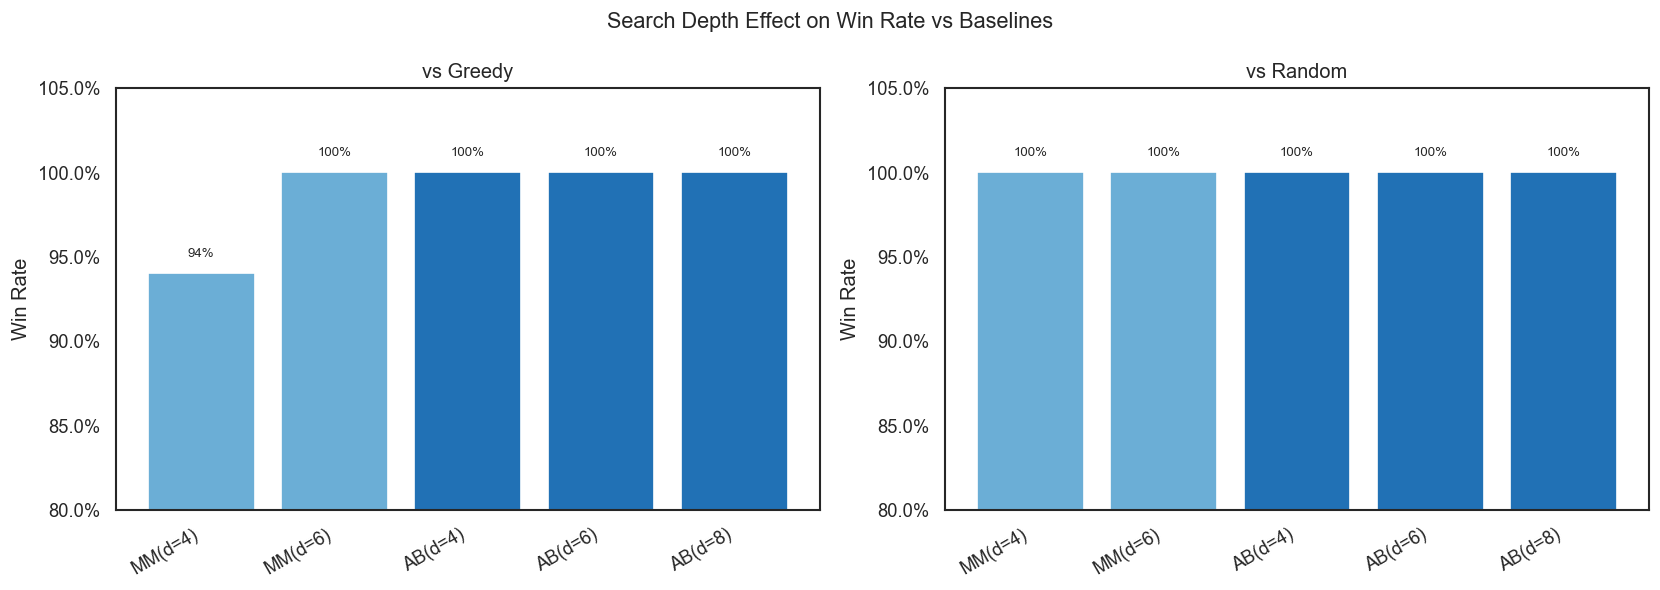

AB(d=6) vs AB(d=8) head-to-head: 50-50-0 (n=100)
  => Depth 6 is the practical ceiling: same strength, ~9x cheaper


In [22]:
depth_agents = ['Minimax(d=4)','Minimax(d=6)',
                'Alpha-Beta(d=4)','Alpha-Beta(d=6)','Alpha-Beta(d=8)']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, opp in zip(axes, ['Greedy', 'Random']):
    for agent in depth_agents:
        res = pairwise_result(v2, agent, opp)
        if not res: continue
        color = agent_color(agent)
        ax.bar(agent.replace('Alpha-Beta','AB').replace('Minimax','MM'),
               res['a_wr'], color=color, edgecolor='white')
        ax.text(agent.replace('Alpha-Beta','AB').replace('Minimax','MM'),
                res['a_wr'] + 0.01, f"{res['a_wr']:.0%}", ha='center', fontsize=8)
    ax.set_ylabel('Win Rate'); ax.set_title(f'vs {opp}')
    ax.set_ylim(0.8, 1.05); ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha='right')

plt.suptitle('Search Depth Effect on Win Rate vs Baselines', fontsize=13)
plt.tight_layout(); plt.show()

# AB(d=6) vs AB(d=8) head-to-head
res_68 = pairwise_result(v2, 'Alpha-Beta(d=6)', 'Alpha-Beta(d=8)')
print(f"AB(d=6) vs AB(d=8) head-to-head: {res_68['a_wins']}-{res_68['b_wins']}-{res_68['draws']} (n={res_68['n']})")
print(f"  => Depth 6 is the practical ceiling: same strength, ~9x cheaper")


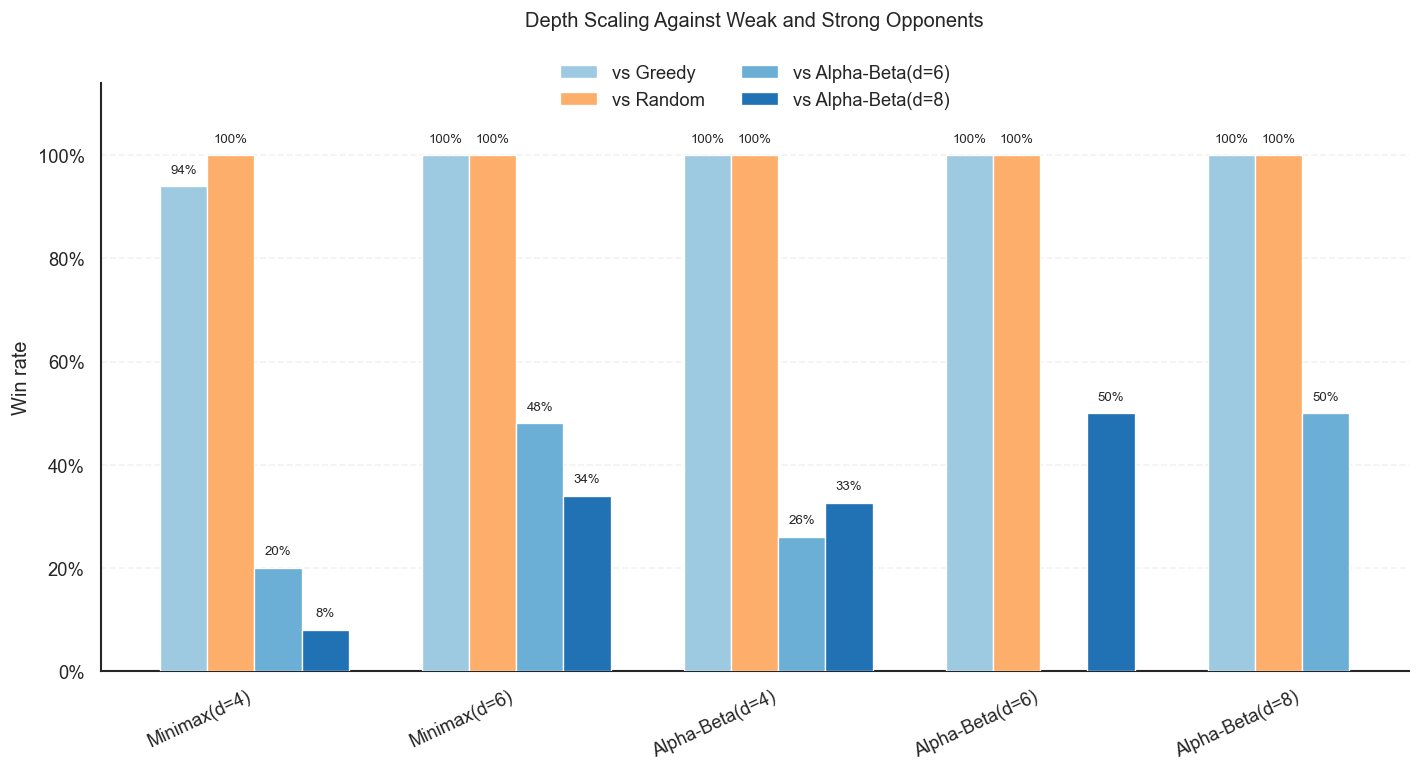

In [23]:
depth_agents = [
    'Minimax(d=4)',
    'Minimax(d=6)',
    'Alpha-Beta(d=4)',
    'Alpha-Beta(d=6)',
    'Alpha-Beta(d=8)',
]

opponents = [
    'Greedy',
    'Random',
    'Alpha-Beta(d=6)',
    'Alpha-Beta(d=8)',
]

rows = []
for agent in depth_agents:
    for opp in opponents:
        if agent == opp:
            rows.append({
                'agent': agent,
                'opp': opp,
                'wr': np.nan,
            })
            continue

        res = pairwise_result(v2, agent, opp)
        rows.append({
            'agent': agent,
            'opp': opp,
            'wr': res['a_wr'] if res else np.nan,
        })

plot_df = pd.DataFrame(rows)

opp_label_map = {
    'Greedy': 'vs Greedy',
    'Random': 'vs Random',
    'Alpha-Beta(d=6)': 'vs Alpha-Beta(d=6)',
    'Alpha-Beta(d=8)': 'vs Alpha-Beta(d=8)',
}

colors = {
    'Greedy': '#9ecae1',
    'Random': '#fdae6b',
    'Alpha-Beta(d=6)': '#6baed6',
    'Alpha-Beta(d=8)': '#2171b5',
}

fig, ax = plt.subplots(figsize=(12, 6.6))
x = np.arange(len(depth_agents))
width = 0.18

for j, opp in enumerate(opponents):
    sub = plot_df[plot_df['opp'] == opp].set_index('agent').loc[depth_agents].reset_index()
    xpos = x + (j - 1.5) * width

    bars = ax.bar(
        xpos,
        sub['wr'],
        width=width,
        color=colors[opp],
        edgecolor='white',
        linewidth=0.8,
        label=opp_label_map[opp],
        zorder=3
    )

    for bar, val in zip(bars, sub['wr']):
        if pd.notna(val):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                val + 0.02,
                f"{val:.0%}",
                ha='center',
                va='bottom',
                fontsize=8
            )

ax.set_title('Depth Scaling Against Weak and Strong Opponents', pad=34)
ax.set_xticks(x)
ax.set_xticklabels(depth_agents, rotation=25, ha='right')
ax.set_ylim(0, 1.14)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylabel('Win rate')
ax.grid(axis='y', linestyle='--', alpha=0.25, zorder=0)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

ax.legend(
    frameon=False,
    ncol=2,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.06)
)

plt.tight_layout()
plt.show()


## 10. Minimax vs Alpha-Beta Efficiency

In [24]:
for depth in [4, 6]:
    mm = f'Minimax(d={depth})'; ab = f'Alpha-Beta(d={depth})'
    res = pairwise_result(v2, mm, ab)
    mm_ms = agent_df[agent_df['agent'] == mm]['avg_ms'].values[0]
    ab_ms = agent_df[agent_df['agent'] == ab]['avg_ms'].values[0]
    speedup = mm_ms / ab_ms if ab_ms > 0 else float('inf')
    print(f"Depth {depth}:")
    print(f"  H2H: MM {res['a_wins']}-{res['b_wins']}-{res['draws']} AB (n={res['n']})")
    print(f"  Timing: MM={mm_ms:.3f} ms, AB={ab_ms:.3f} ms => {speedup:.1f}x speedup")
    print(f"  Same competitive strength, {speedup:.0f}x faster with pruning")
    print()


Depth 4:
  H2H: MM 27-22-1 AB (n=50)
  Timing: MM=0.019 ms, AB=0.006 ms => 3.2x speedup
  Same competitive strength, 3x faster with pruning

Depth 6:
  H2H: MM 24-25-1 AB (n=50)
  Timing: MM=1.076 ms, AB=0.065 ms => 16.4x speedup
  Same competitive strength, 16x faster with pruning



## 12. Extra Turns & Captures Analysis

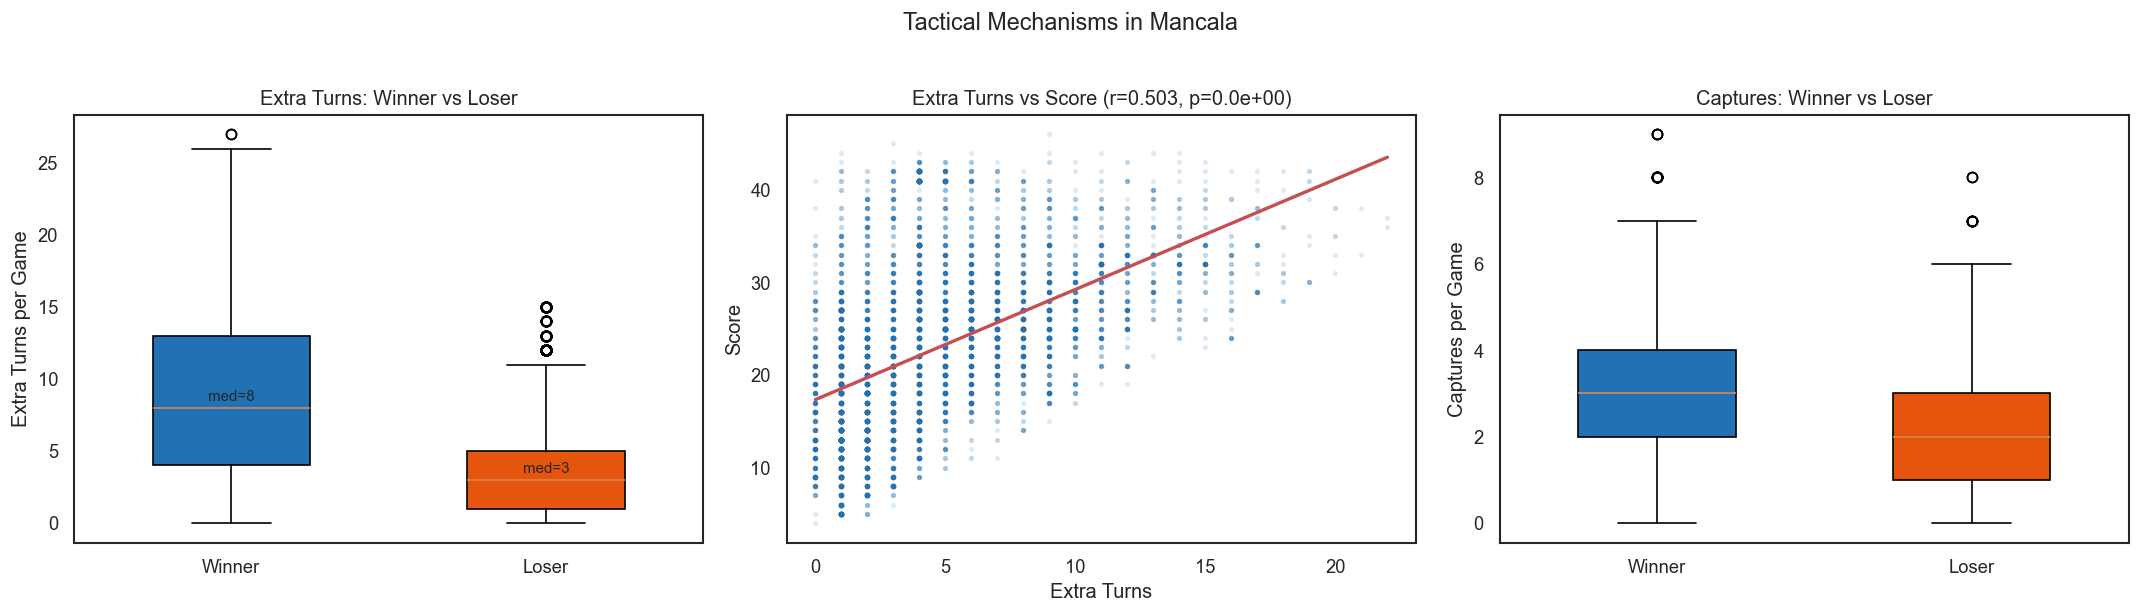

Winner avg extra turns: 9.03
Loser avg extra turns:  3.64
Ratio: 2.5x

Winner avg captures: 3.04
Loser avg captures:  2.22


In [25]:
decided = v2[v2['winner'] != 'draw'].copy()
decided['winner_et'] = np.where(decided['winner']=='p1', decided['p1_extra_turns'], decided['p2_extra_turns'])
decided['loser_et'] = np.where(decided['winner']=='p1', decided['p2_extra_turns'], decided['p1_extra_turns'])
decided['winner_cap'] = np.where(decided['winner']=='p1', decided['p1_captures'], decided['p2_captures'])
decided['loser_cap'] = np.where(decided['winner']=='p1', decided['p2_captures'], decided['p1_captures'])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Extra turns: winner vs loser
ax = axes[0]
positions = [1, 2]
bp = ax.boxplot([decided['winner_et'], decided['loser_et']], positions=positions,
                widths=0.5, patch_artist=True)
bp['boxes'][0].set_facecolor('#2171b5'); bp['boxes'][1].set_facecolor('#e6550d')
ax.set_xticks(positions); ax.set_xticklabels(['Winner', 'Loser'])
ax.set_ylabel('Extra Turns per Game'); ax.set_title('Extra Turns: Winner vs Loser')
ax.text(1, decided['winner_et'].median()+0.5, f"med={decided['winner_et'].median():.0f}", ha='center', fontsize=9)
ax.text(2, decided['loser_et'].median()+0.5, f"med={decided['loser_et'].median():.0f}", ha='center', fontsize=9)

# Scatter: extra turns vs score
ax = axes[1]
ax.scatter(v2['p1_extra_turns'], v2['p1_score'], alpha=0.1, s=5, color='#2171b5')
r, p_val = stats.pearsonr(v2['p1_extra_turns'], v2['p1_score'])
z = np.polyfit(v2['p1_extra_turns'], v2['p1_score'], 1)
x_line = np.linspace(0, v2['p1_extra_turns'].max(), 100)
ax.plot(x_line, np.polyval(z, x_line), 'r-', linewidth=2)
ax.set_xlabel('Extra Turns'); ax.set_ylabel('Score')
ax.set_title(f'Extra Turns vs Score (r={r:.3f}, p={p_val:.1e})')

# Captures: winner vs loser
ax = axes[2]
bp2 = ax.boxplot([decided['winner_cap'], decided['loser_cap']], positions=positions,
                 widths=0.5, patch_artist=True)
bp2['boxes'][0].set_facecolor('#2171b5'); bp2['boxes'][1].set_facecolor('#e6550d')
ax.set_xticks(positions); ax.set_xticklabels(['Winner', 'Loser'])
ax.set_ylabel('Captures per Game'); ax.set_title('Captures: Winner vs Loser')

plt.suptitle('Tactical Mechanisms in Mancala', fontsize=14, y=1.02)
plt.tight_layout(); plt.show()

print(f"Winner avg extra turns: {decided['winner_et'].mean():.2f}")
print(f"Loser avg extra turns:  {decided['loser_et'].mean():.2f}")
print(f"Ratio: {decided['winner_et'].mean()/decided['loser_et'].mean():.1f}x")
print(f"\nWinner avg captures: {decided['winner_cap'].mean():.2f}")
print(f"Loser avg captures:  {decided['loser_cap'].mean():.2f}")


In [26]:
decided = v2[v2['winner'] != 'draw'].copy()
decided['winner_et'] = np.where(decided['winner']=='p1', decided['p1_extra_turns'], decided['p2_extra_turns'])
decided['loser_et'] = np.where(decided['winner']=='p1', decided['p2_extra_turns'], decided['p1_extra_turns'])
decided['winner_cap'] = np.where(decided['winner']=='p1', decided['p1_captures'], decided['p2_captures'])
decided['loser_cap'] = np.where(decided['winner']=='p1', decided['p2_captures'], decided['p1_captures'])

decided['winner_agent'] = np.where(decided['winner'] == 'p1', decided['p1_label'], decided['p2_label'])

def agent_family(agent):
    if 'Alpha-Beta' in agent:
        return 'Alpha-Beta'
    if 'Minimax' in agent:
        return 'Minimax'
    if 'MCTS' in agent:
        return 'MCTS'
    if 'Greedy' in agent:
        return 'Greedy'
    return 'Other'

decided['winner_family'] = decided['winner_agent'].apply(agent_family)


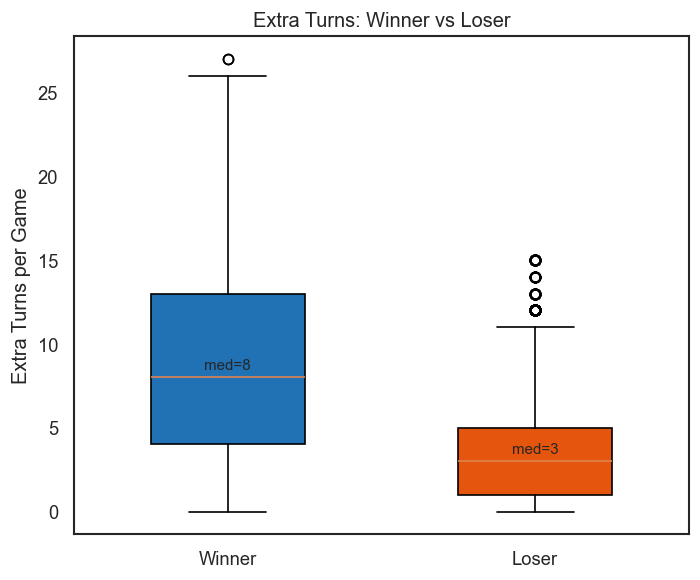

Winner avg extra turns: 9.03
Loser avg extra turns:  3.64
Ratio: 2.5x


In [27]:
#  Extra turns, winner vs loser
fig, ax = plt.subplots(figsize=(6, 5))

positions = [1, 2]
bp = ax.boxplot(
    [decided['winner_et'], decided['loser_et']],
    positions=positions,
    widths=0.5,
    patch_artist=True
)

bp['boxes'][0].set_facecolor('#2171b5')
bp['boxes'][1].set_facecolor('#e6550d')

ax.set_xticks(positions)
ax.set_xticklabels(['Winner', 'Loser'])
ax.set_ylabel('Extra Turns per Game')
ax.set_title('Extra Turns: Winner vs Loser')

ax.text(1, decided['winner_et'].median() + 0.5,
        f"med={decided['winner_et'].median():.0f}",
        ha='center', fontsize=9)
ax.text(2, decided['loser_et'].median() + 0.5,
        f"med={decided['loser_et'].median():.0f}",
        ha='center', fontsize=9)

plt.tight_layout()
plt.show()

print(f"Winner avg extra turns: {decided['winner_et'].mean():.2f}")
print(f"Loser avg extra turns:  {decided['loser_et'].mean():.2f}")
print(f"Ratio: {decided['winner_et'].mean()/decided['loser_et'].mean():.1f}x")


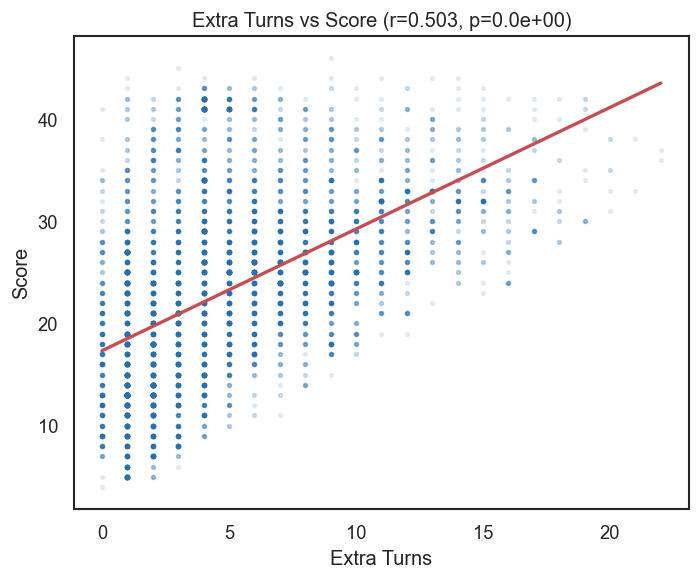

In [28]:
# Extra turns vs score
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(
    v2['p1_extra_turns'],
    v2['p1_score'],
    alpha=0.1,
    s=5,
    color='#2171b5'
)

r, p_val = stats.pearsonr(v2['p1_extra_turns'], v2['p1_score'])
z = np.polyfit(v2['p1_extra_turns'], v2['p1_score'], 1)
x_line = np.linspace(0, v2['p1_extra_turns'].max(), 100)

ax.plot(x_line, np.polyval(z, x_line), 'r-', linewidth=2)

ax.set_xlabel('Extra Turns')
ax.set_ylabel('Score')
ax.set_title(f'Extra Turns vs Score (r={r:.3f}, p={p_val:.1e})')

plt.tight_layout()
plt.show()


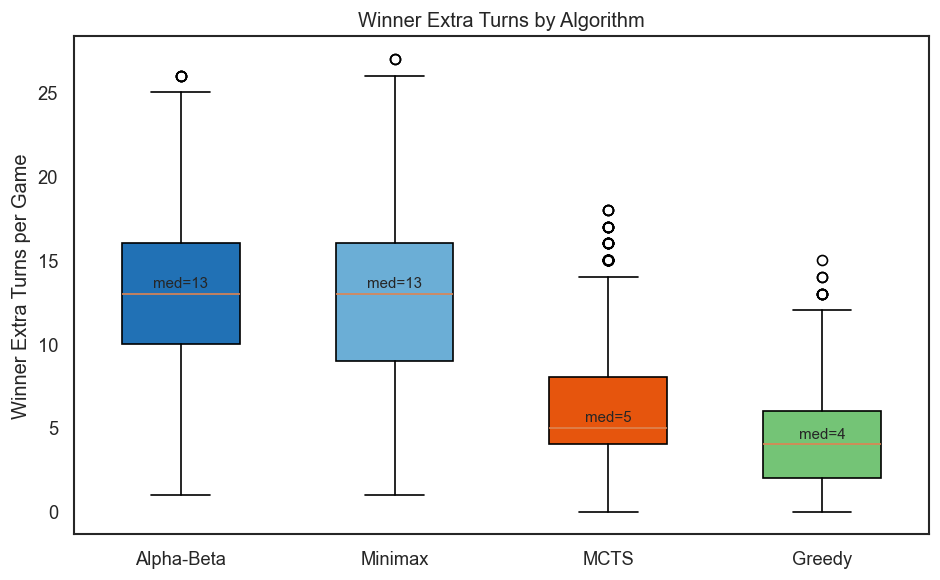

,count,mean,median
winner_family,,,
Alpha-Beta,3320,12.736145,13.0
Minimax,1069,12.292797,13.0
MCTS,4345,5.559954,5.0
Greedy,164,4.597561,4.0


In [29]:
# Winner extra turns by algorithm family
families = ['Alpha-Beta', 'Minimax', 'MCTS', 'Greedy']
colors = ['#2171b5', '#6baed6', '#e6550d', '#74c476']

plot_data = [
    decided.loc[decided['winner_family'] == fam, 'winner_et'].dropna()
    for fam in families
]

fig, ax = plt.subplots(figsize=(8, 5))

bp = ax.boxplot(
    plot_data,
    positions=range(1, len(families) + 1),
    widths=0.55,
    patch_artist=True
)

for box, color in zip(bp['boxes'], colors):
    box.set_facecolor(color)

ax.set_xticks(range(1, len(families) + 1))
ax.set_xticklabels(families)
ax.set_ylabel('Winner Extra Turns per Game')
ax.set_title('Winner Extra Turns by Algorithm')

for i, series in enumerate(plot_data, start=1):
    if len(series) > 0:
        ax.text(i, series.median() + 0.4, f"med={series.median():.0f}",
                ha='center', fontsize=9)

plt.tight_layout()
plt.show()

decided.groupby('winner_family')['winner_et'].agg(['count', 'mean', 'median']).reindex(families)


## 13. Score Distributions

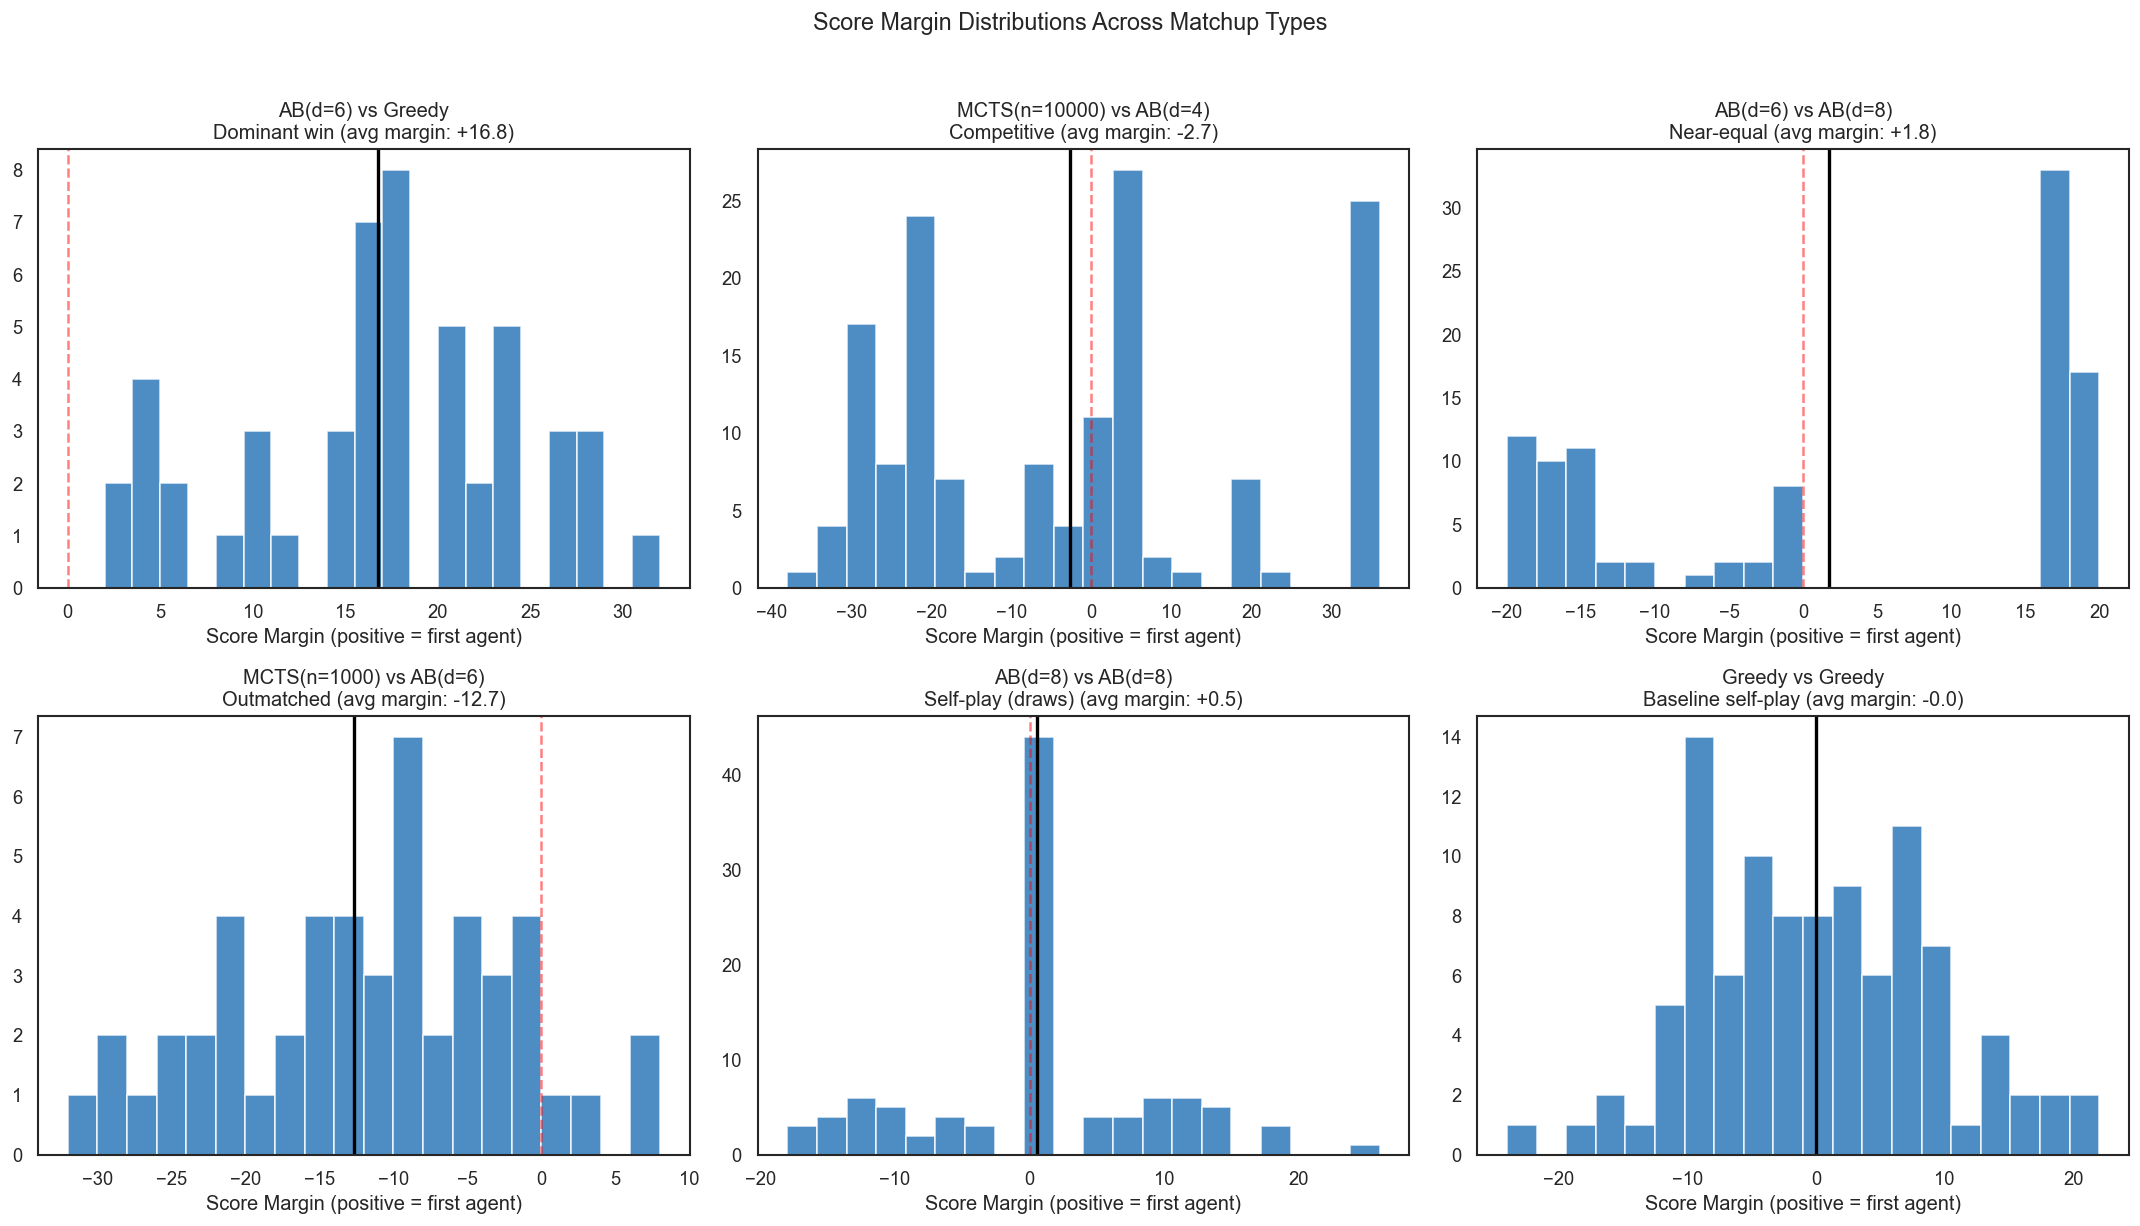

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sample_matchups = [
    ('Alpha-Beta(d=6)', 'Greedy', 'Dominant win'),
    ('MCTS(n=10000)', 'Alpha-Beta(d=4)', 'Competitive'),
    ('Alpha-Beta(d=6)', 'Alpha-Beta(d=8)', 'Near-equal'),
    ('MCTS(n=1000)', 'Alpha-Beta(d=6)', 'Outmatched'),
    ('Alpha-Beta(d=8)', 'Alpha-Beta(d=8)', 'Self-play (draws)'),
    ('Greedy', 'Greedy', 'Baseline self-play'),
]

for ax, (a, b, title) in zip(axes.flat, sample_matchups):
    sub = v2[((v2['p1_label']==a) & (v2['p2_label']==b)) |
             ((v2['p1_label']==b) & (v2['p2_label']==a))]
    if len(sub) == 0:
        ax.text(0.5, 0.5, 'No data', transform=ax.transAxes, ha='center')
        ax.set_title(title); continue

    # Compute margin from a's perspective
    margins = []
    for _, row in sub.iterrows():
        if row['p1_label'] == a:
            margins.append(row['p1_score'] - row['p2_score'])
        else:
            margins.append(row['p2_score'] - row['p1_score'])

    ax.hist(margins, bins=20, color='#2171b5', edgecolor='white', alpha=0.8)
    ax.axvline(0, color='red', linestyle='--', alpha=0.5)
    ax.axvline(np.mean(margins), color='black', linestyle='-', linewidth=2)
    short_a = a.replace('Alpha-Beta','AB').replace('Minimax','MM')
    short_b = b.replace('Alpha-Beta','AB').replace('Minimax','MM')
    ax.set_title(f'{short_a} vs {short_b}\n{title} (avg margin: {np.mean(margins):+.1f})')
    ax.set_xlabel('Score Margin (positive = first agent)')

plt.suptitle('Score Margin Distributions Across Matchup Types', fontsize=14, y=1.02)
plt.tight_layout(); plt.show()


## 14. Pareto Frontier: Win Rate vs Computation Cost

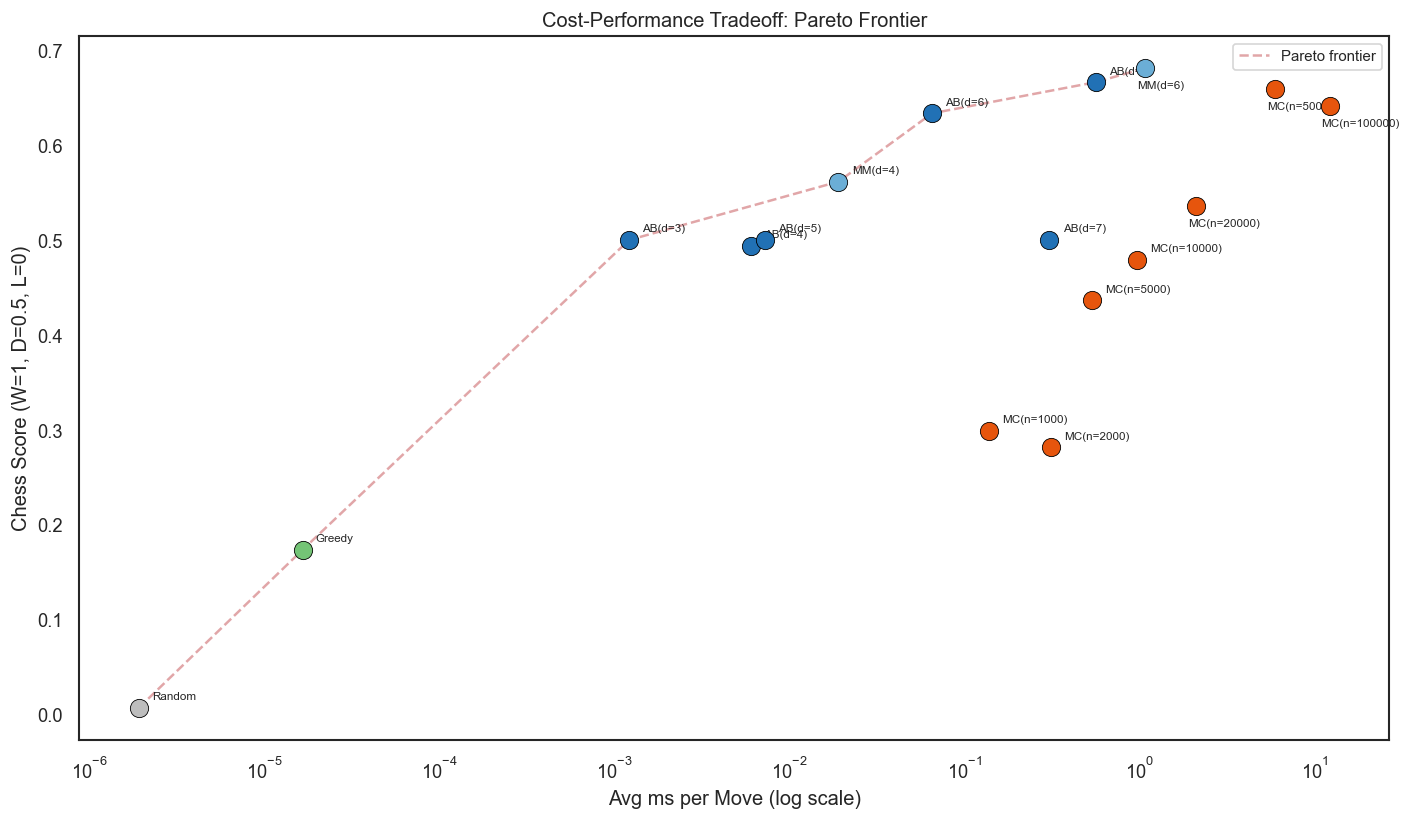

In [31]:
fig, ax = plt.subplots(figsize=(12, 7))

# Filter to "core" agents (no C variants, no rich variants)
core = agent_df[~agent_df['agent'].str.contains(',C=|,rich')].copy()
core['log_ms'] = np.log10(core['avg_ms'].clip(lower=1e-4))

for _, row in core.iterrows():
    color = agent_color(row['agent'])
    ax.scatter(row['avg_ms'], row['chess_score'], s=120, c=color,
               edgecolors='black', linewidth=0.5, zorder=5)
    # Label
    short = row['agent'].replace('Alpha-Beta','AB').replace('Minimax','MM').replace('MCTS','MC')
    offset = (8, 5) if row['avg_ms'] < 1 else (-5, -12)
    ax.annotate(short, (row['avg_ms'], row['chess_score']),
                textcoords='offset points', xytext=offset, fontsize=7)

# Pareto frontier
pareto = core.sort_values('avg_ms')
frontier = []
best_score = -1
for _, row in pareto.iterrows():
    if row['chess_score'] > best_score:
        frontier.append(row)
        best_score = row['chess_score']
if frontier:
    fx = [r['avg_ms'] for r in frontier]
    fy = [r['chess_score'] for r in frontier]
    ax.plot(fx, fy, 'r--', linewidth=1.5, alpha=0.5, label='Pareto frontier')

ax.set_xscale('log')
ax.set_xlabel('Avg ms per Move (log scale)')
ax.set_ylabel('Chess Score (W=1, D=0.5, L=0)')
ax.set_title('Cost-Performance Tradeoff: Pareto Frontier')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()


## 15. Head-to-Head Heatmap

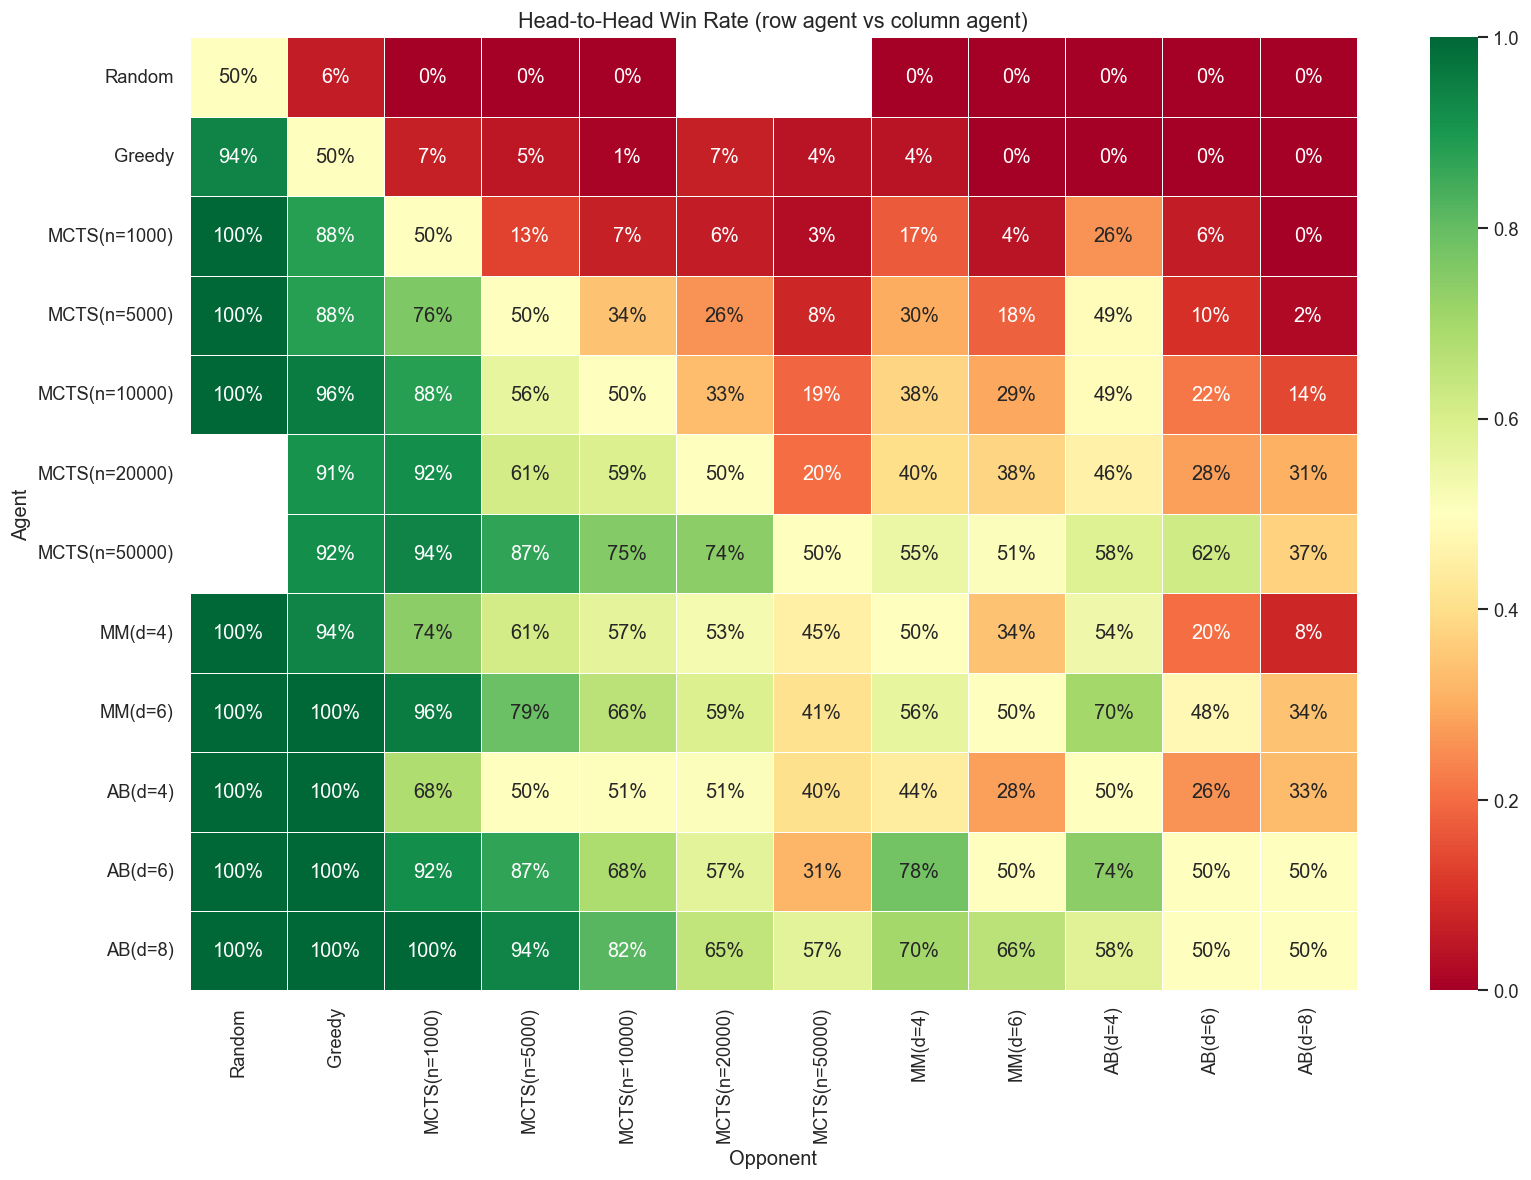

In [32]:
# Build pairwise win rate matrix for core agents
core_agents = ['Random','Greedy','MCTS(n=1000)','MCTS(n=5000)','MCTS(n=10000)',
               'MCTS(n=20000)','MCTS(n=50000)','Minimax(d=4)','Minimax(d=6)',
               'Alpha-Beta(d=4)','Alpha-Beta(d=6)','Alpha-Beta(d=8)']

matrix = pd.DataFrame(index=core_agents, columns=core_agents, dtype=float)
n_matrix = pd.DataFrame(index=core_agents, columns=core_agents, dtype=float)

for a in core_agents:
    for b in core_agents:
        if a == b:
            matrix.loc[a, b] = 0.5
            n_matrix.loc[a, b] = 0
            continue
        res = pairwise_result(v2, a, b)
        if res:
            matrix.loc[a, b] = res['a_wr']
            n_matrix.loc[a, b] = res['n']
        else:
            matrix.loc[a, b] = np.nan
            n_matrix.loc[a, b] = 0

fig, ax = plt.subplots(figsize=(14, 10))
short_labels = [a.replace('Alpha-Beta','AB').replace('Minimax','MM') for a in core_agents]
mask = matrix.isna()

sns.heatmap(matrix.astype(float), annot=True, fmt='.0%', cmap='RdYlGn', center=0.5,
            vmin=0, vmax=1, mask=mask, linewidths=0.5,
            xticklabels=short_labels, yticklabels=short_labels, ax=ax)
ax.set_title('Head-to-Head Win Rate (row agent vs column agent)', fontsize=13)
ax.set_xlabel('Opponent'); ax.set_ylabel('Agent')
plt.tight_layout(); plt.show()


## 16. Game Length Analysis

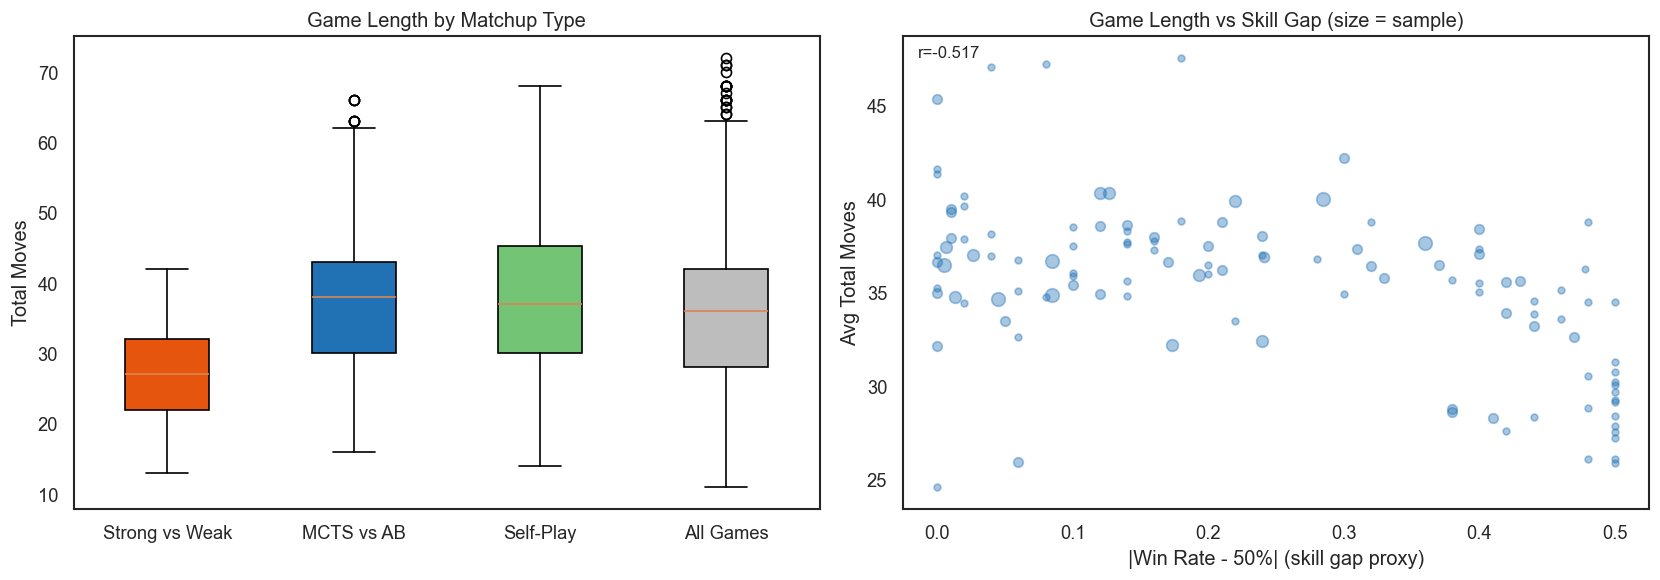

Overall avg game length: 35.7 moves
Self-play AB(d=8): 36.2 moves


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Game length by matchup type
ax = axes[0]
categories = {
    'Strong vs Weak': v2[v2['matchup_label'].isin([
        'Alpha-Beta(d=6) vs Random', 'Alpha-Beta(d=8) vs Greedy'])],
    'MCTS vs AB': v2[v2['matchup_label'].str.contains('MCTS.*Alpha-Beta|Alpha-Beta.*MCTS')],
    'Self-Play': v2[v2['p1_label'] == v2['p2_label']],
    'All Games': v2,
}
data = [cat['total_moves'].values for cat in categories.values()]
labels = list(categories.keys())
bp = ax.boxplot(data, labels=labels, patch_artist=True)
colors_bp = ['#e6550d', '#2171b5', '#74c476', '#bdbdbd']
for patch, color in zip(bp['boxes'], colors_bp):
    patch.set_facecolor(color)
ax.set_ylabel('Total Moves'); ax.set_title('Game Length by Matchup Type')

# Game length vs skill gap
ax = axes[1]
for _, row in matchup_df.iterrows():
    skill_gap = abs(row['p1_wr'] - 0.5)
    ax.scatter(skill_gap, row['moves'], s=row['n']/3, alpha=0.4, color='#2171b5')
ax.set_xlabel('|Win Rate - 50%| (skill gap proxy)')
ax.set_ylabel('Avg Total Moves')
ax.set_title('Game Length vs Skill Gap (size = sample)')
r, p = stats.pearsonr(matchup_df['p1_wr'].apply(lambda x: abs(x-0.5)), matchup_df['moves'])
ax.text(0.02, 0.98, f'r={r:.3f}', transform=ax.transAxes, va='top', fontsize=10)

plt.tight_layout(); plt.show()
print(f"Overall avg game length: {v2['total_moves'].mean():.1f} moves")
print(f"Self-play AB(d=8): {v2[(v2['p1_label']=='Alpha-Beta(d=8)') & (v2['p2_label']=='Alpha-Beta(d=8)')]['total_moves'].mean():.1f} moves")


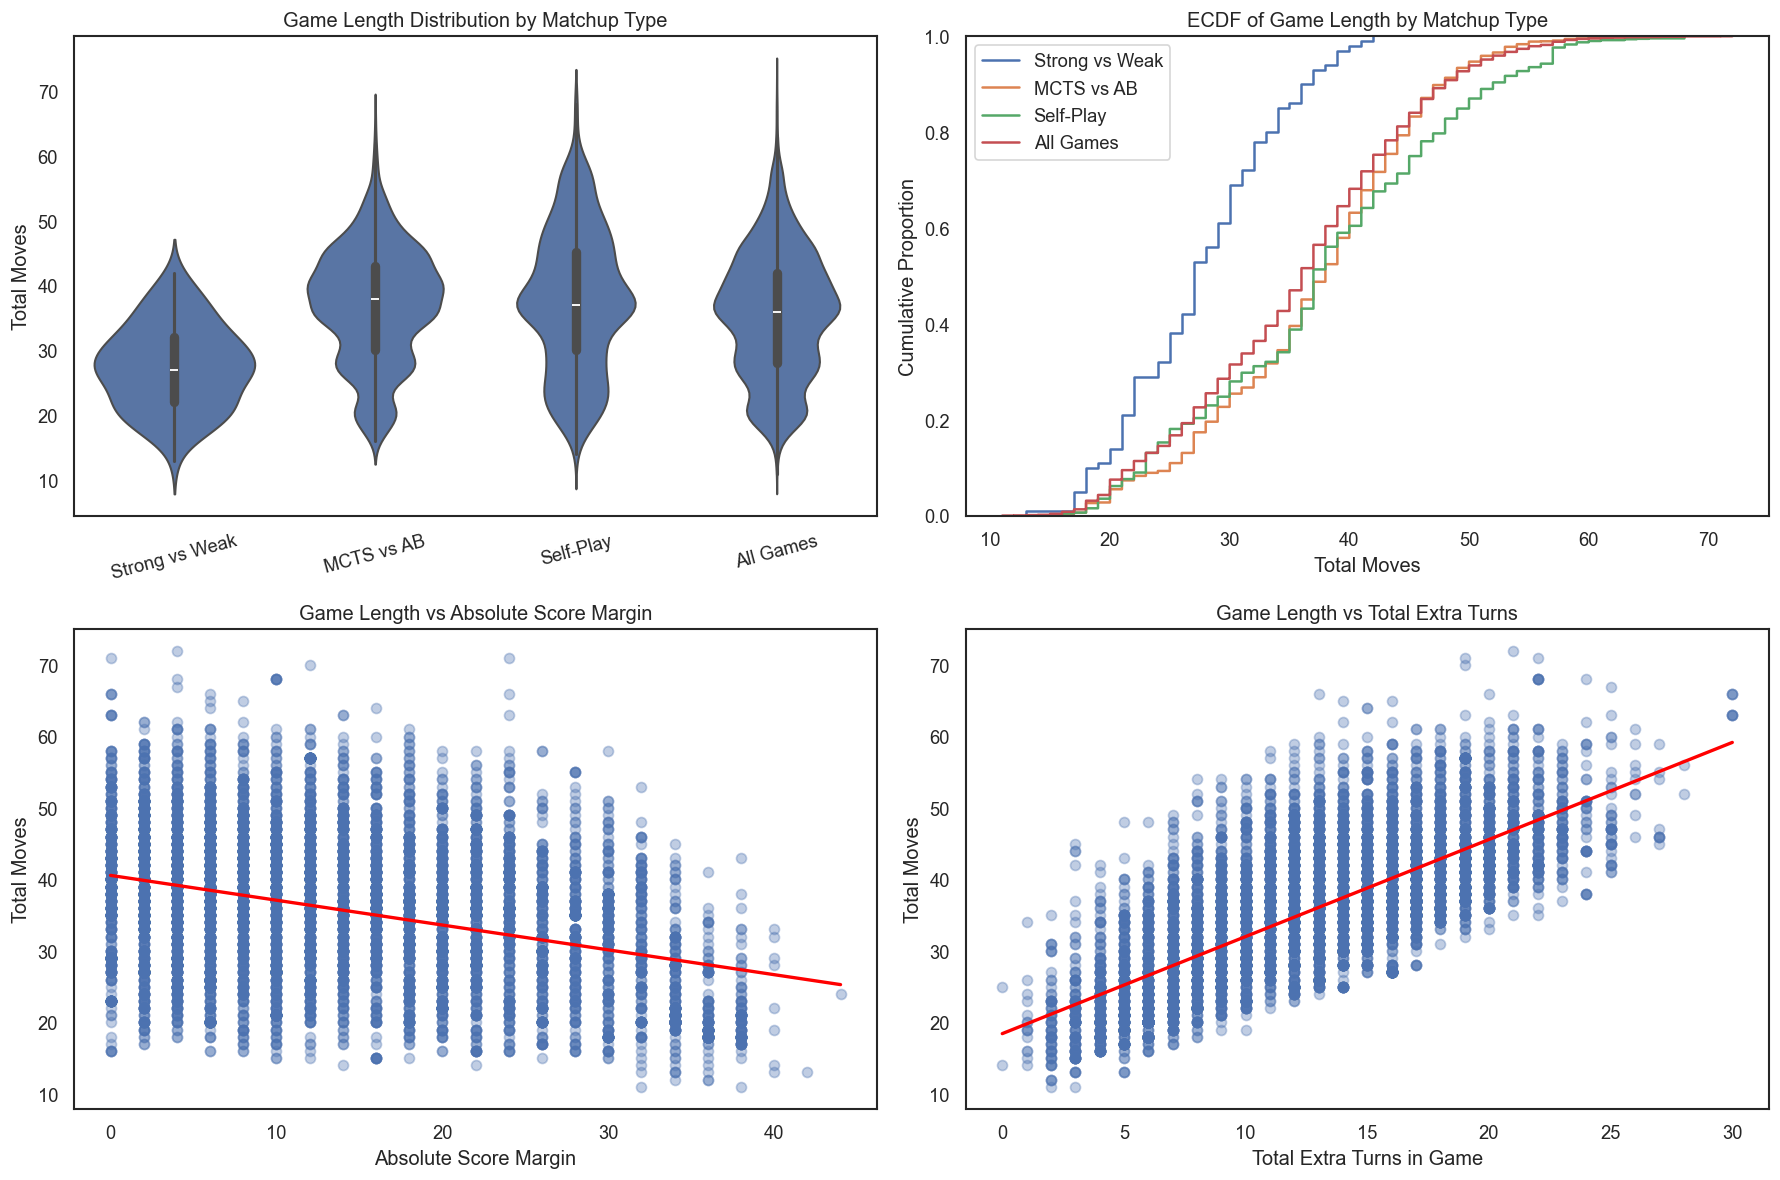

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

plot_v2 = v2.copy()
plot_v2['score_margin'] = (plot_v2['p1_score'] - plot_v2['p2_score']).abs()
plot_v2['total_extra_turns'] = plot_v2['p1_extra_turns'] + plot_v2['p2_extra_turns']
plot_v2['total_captures'] = plot_v2['p1_captures'] + plot_v2['p2_captures']

categories = {
    'Strong vs Weak': v2[v2['matchup_label'].isin([
        'Alpha-Beta(d=6) vs Random', 'Alpha-Beta(d=8) vs Greedy'])],
    'MCTS vs AB': v2[v2['matchup_label'].str.contains('MCTS.*Alpha-Beta|Alpha-Beta.*MCTS')],
    'Self-Play': v2[v2['p1_label'] == v2['p2_label']],
    'All Games': v2,
}

# Violin plot: distribution of game length
ax = axes[0, 0]
plot_df = pd.concat([
    pd.DataFrame({'group': name, 'total_moves': df['total_moves']})
    for name, df in categories.items()
], ignore_index=True)

sns.violinplot(data=plot_df, x='group', y='total_moves', inner='box', ax=ax)
ax.set_title('Game Length Distribution by Matchup Type')
ax.set_xlabel('')
ax.set_ylabel('Total Moves')
ax.tick_params(axis='x', rotation=15)

# ECDF plot: compare full distributions (Empirical Cumulative Distribution Function)
ax = axes[0, 1]
for name, df in categories.items():
    sns.ecdfplot(df['total_moves'], ax=ax, label=name)
ax.set_title('ECDF of Game Length by Matchup Type')
ax.set_xlabel('Total Moves')
ax.set_ylabel('Cumulative Proportion')
ax.legend()

# Game length vs score margin
ax = axes[1, 0]
x = plot_v2['score_margin'].to_numpy()
y = plot_v2['total_moves'].to_numpy()

ax.scatter(x, y, alpha=0.35)

# fitted line
m, b = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 200)
y_line = m * x_line + b
ax.plot(x_line, y_line, linewidth=2, color = "red")

ax.set_title('Game Length vs Absolute Score Margin')
ax.set_xlabel('Absolute Score Margin')
ax.set_ylabel('Total Moves')

# Game length vs total extra turns
ax = axes[1, 1]
x = plot_v2['total_extra_turns'].to_numpy()
y = plot_v2['total_moves'].to_numpy()

ax.scatter(x, y, alpha=0.35)

# fitted line
m, b = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 200)
y_line = m * x_line + b
ax.plot(x_line, y_line, linewidth=2, color = "red")

ax.set_title('Game Length vs Total Extra Turns')
ax.set_xlabel('Total Extra Turns in Game')
ax.set_ylabel('Total Moves')


plt.tight_layout()
plt.show()

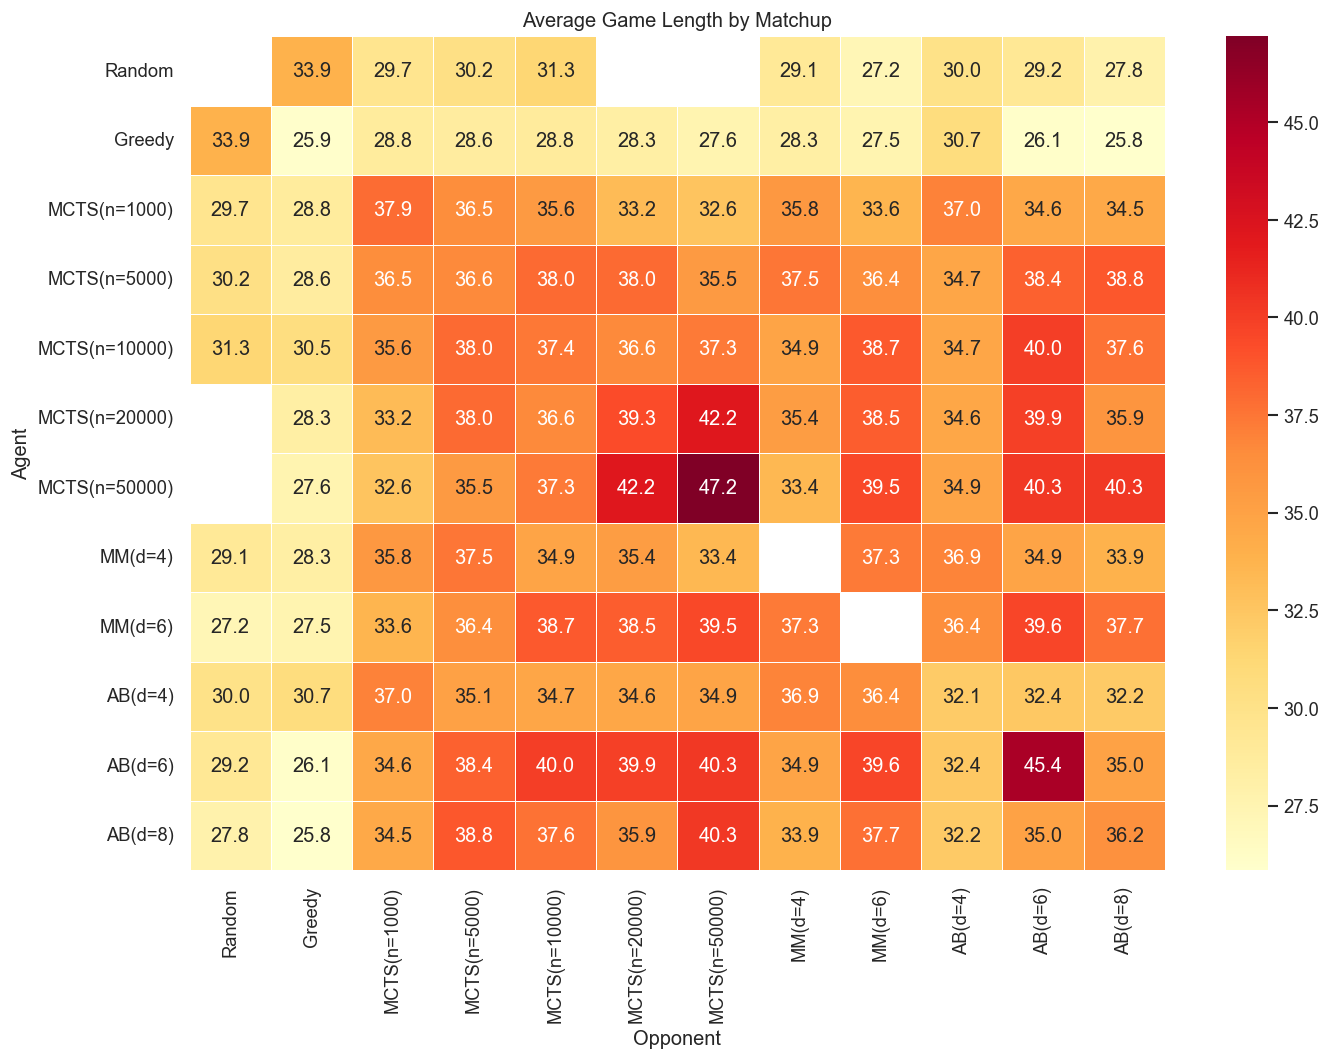

In [35]:
# Average game length heatmap
length_matrix = pd.DataFrame(index=core_agents, columns=core_agents, dtype=float)

for a in core_agents:
    for b in core_agents:
        subset = v2[(v2['p1_label'] == a) & (v2['p2_label'] == b)]
        if len(subset) > 0:
            length_matrix.loc[a, b] = subset['total_moves'].mean()
        else:
            subset_rev = v2[(v2['p1_label'] == b) & (v2['p2_label'] == a)]
            if len(subset_rev) > 0:
                length_matrix.loc[a, b] = subset_rev['total_moves'].mean()
            else:
                length_matrix.loc[a, b] = np.nan

short_labels = [a.replace('Alpha-Beta', 'AB').replace('Minimax', 'MM') for a in core_agents]

plt.figure(figsize=(12, 9))
sns.heatmap(
    length_matrix.astype(float),
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    xticklabels=short_labels,
    yticklabels=short_labels
)
plt.title('Average Game Length by Matchup')
plt.xlabel('Opponent')
plt.ylabel('Agent')
plt.tight_layout()
plt.show()

## 17. Elo Sensitivity Analysis

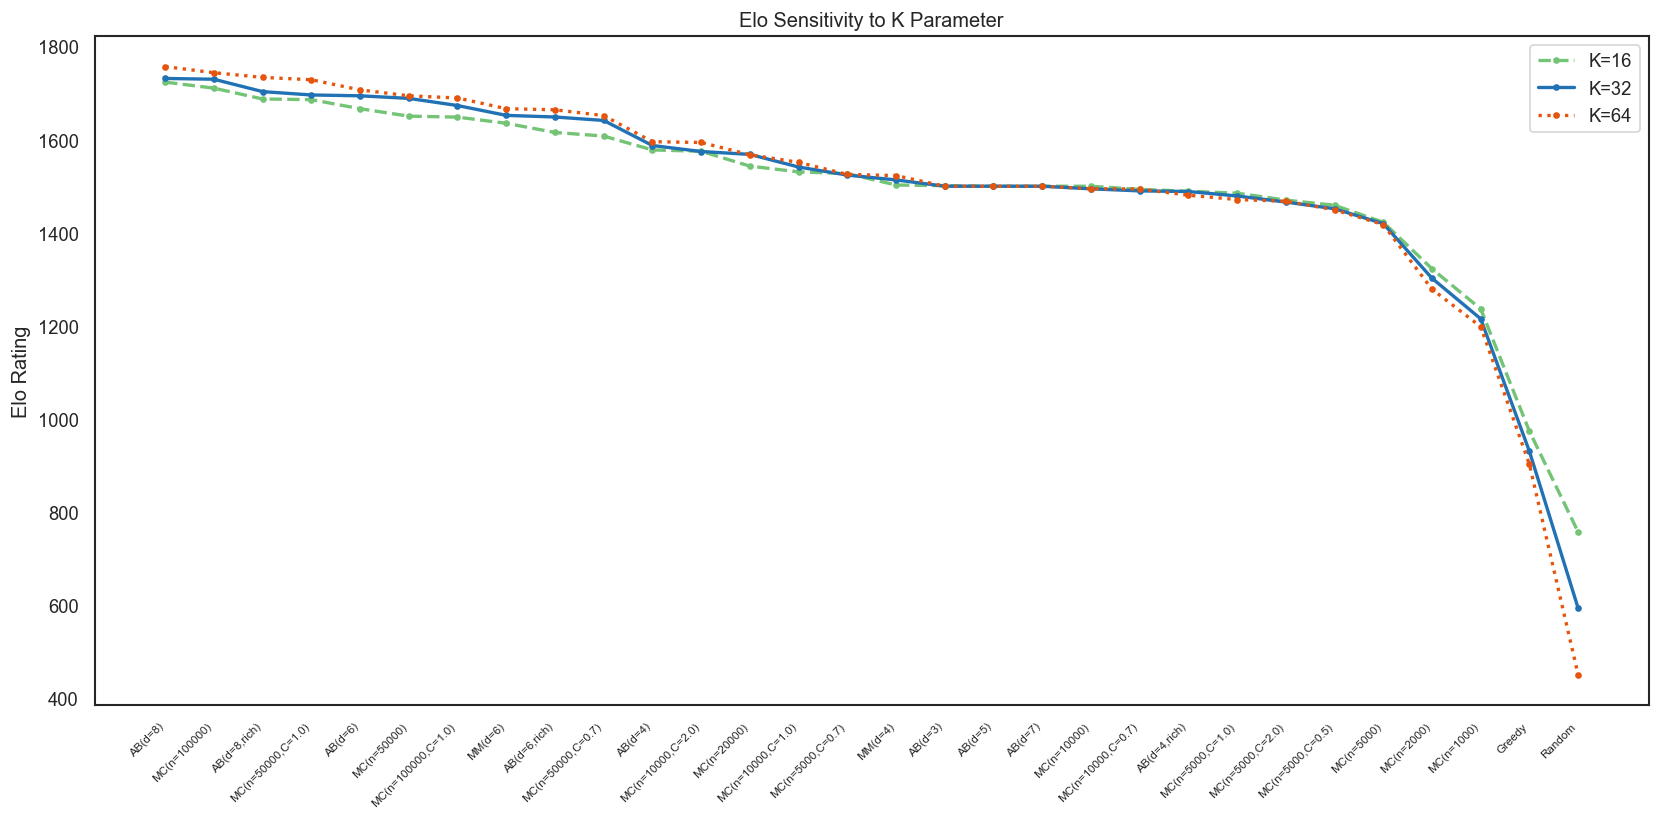

Spearman rank correlation: K=16 vs K=32: 0.9902
Spearman rank correlation: K=32 vs K=64: 0.9973


In [36]:
# Test K sensitivity
fig, ax = plt.subplots(figsize=(14, 7))
for k_val, color, ls in [(16, '#74c476', '--'), (32, '#2171b5', '-'), (64, '#e6550d', ':')]:
    runs = [compute_elo(v2.sample(frac=1, random_state=i), k=k_val) for i in range(10)]
    avg = {a: np.mean([e.get(a, 1500) for e in runs]) for a in all_agents}
    sorted_agents = sorted(avg.items(), key=lambda x: -x[1])
    ax.plot(range(len(sorted_agents)), [e for _, e in sorted_agents],
            color=color, linestyle=ls, linewidth=2, marker='o', markersize=3, label=f'K={k_val}')

ax.set_xticks(range(len(sorted_agents)))
ax.set_xticklabels([a.replace('Alpha-Beta','AB').replace('Minimax','MM').replace('MCTS','MC')
                     for a, _ in sorted_agents], rotation=45, ha='right', fontsize=7)
ax.set_ylabel('Elo Rating'); ax.set_title('Elo Sensitivity to K Parameter')
ax.legend(); plt.tight_layout(); plt.show()

# Print rank correlation across K values
from scipy.stats import spearmanr
runs_16 = [compute_elo(v2.sample(frac=1, random_state=i), k=16) for i in range(10)]
runs_64 = [compute_elo(v2.sample(frac=1, random_state=i), k=64) for i in range(10)]
avg_16 = {a: np.mean([e.get(a, 1500) for e in runs_16]) for a in all_agents}
avg_64 = {a: np.mean([e.get(a, 1500) for e in runs_64]) for a in all_agents}
r16 = [avg_16[a] for a in all_agents]
r32 = [elo_avg[a] for a in all_agents]
r64 = [avg_64[a] for a in all_agents]
rho_16_32, _ = spearmanr(r16, r32)
rho_32_64, _ = spearmanr(r32, r64)
print(f"Spearman rank correlation: K=16 vs K=32: {rho_16_32:.4f}")
print(f"Spearman rank correlation: K=32 vs K=64: {rho_32_64:.4f}")


## 18. Summary of Key Findings

| Research Question | Finding |
|---|---|
| Does AB pruning improve on Minimax? | Yes: 3x-17x speedup, no competitive penalty |
| How does depth affect quality? | Ceiling at d=6; d=8 adds 9x cost for no benefit |
| How does MCTS budget affect quality? | Scales with N; ~50,000 sims needed to match AB(d=6) |
| Can MCTS compete with deep AB? | Only at high budgets; AB dominates at moderate compute |
| Optimal MCTS exploration constant? | C=1.4 (default) is robust; low-C advantage in v1 was artifact |
| Does richer eval help? | Converges at d>=6; deeper search beats richer eval |
| First-mover advantage? | Universal; stronger agents exploit it more |
| v1 vs v2 impact? | Depth extension was most consequential; reversed MCTS vs AB results |
| Overall ranking? | AB(d=8) > AB(d=6) ~= AB(d=8,rich) > MCTS(50k) > MM(d=6) |
| Cost-performance? | AB(d=6) is Pareto-optimal: top-tier strength at 0.07 ms/move |


Predictive Modeling
Logistic regression on MCTS scaling; logit-linear on AB depth.

MCTS Logistic Predictions:

Opponent               R²            200k            500k              1M
------------------------------------------------------------------------
Alpha-Beta(d=4)     0.740   66% [56%,75%]   71% [60%,82%]   75% [63%,87%]
Alpha-Beta(d=6)     0.863   68% [53%,83%]   80% [64%,96%]  86% [72%,100%]
Alpha-Beta(d=8)     0.920   61% [51%,70%]   74% [63%,85%]   82% [72%,93%]


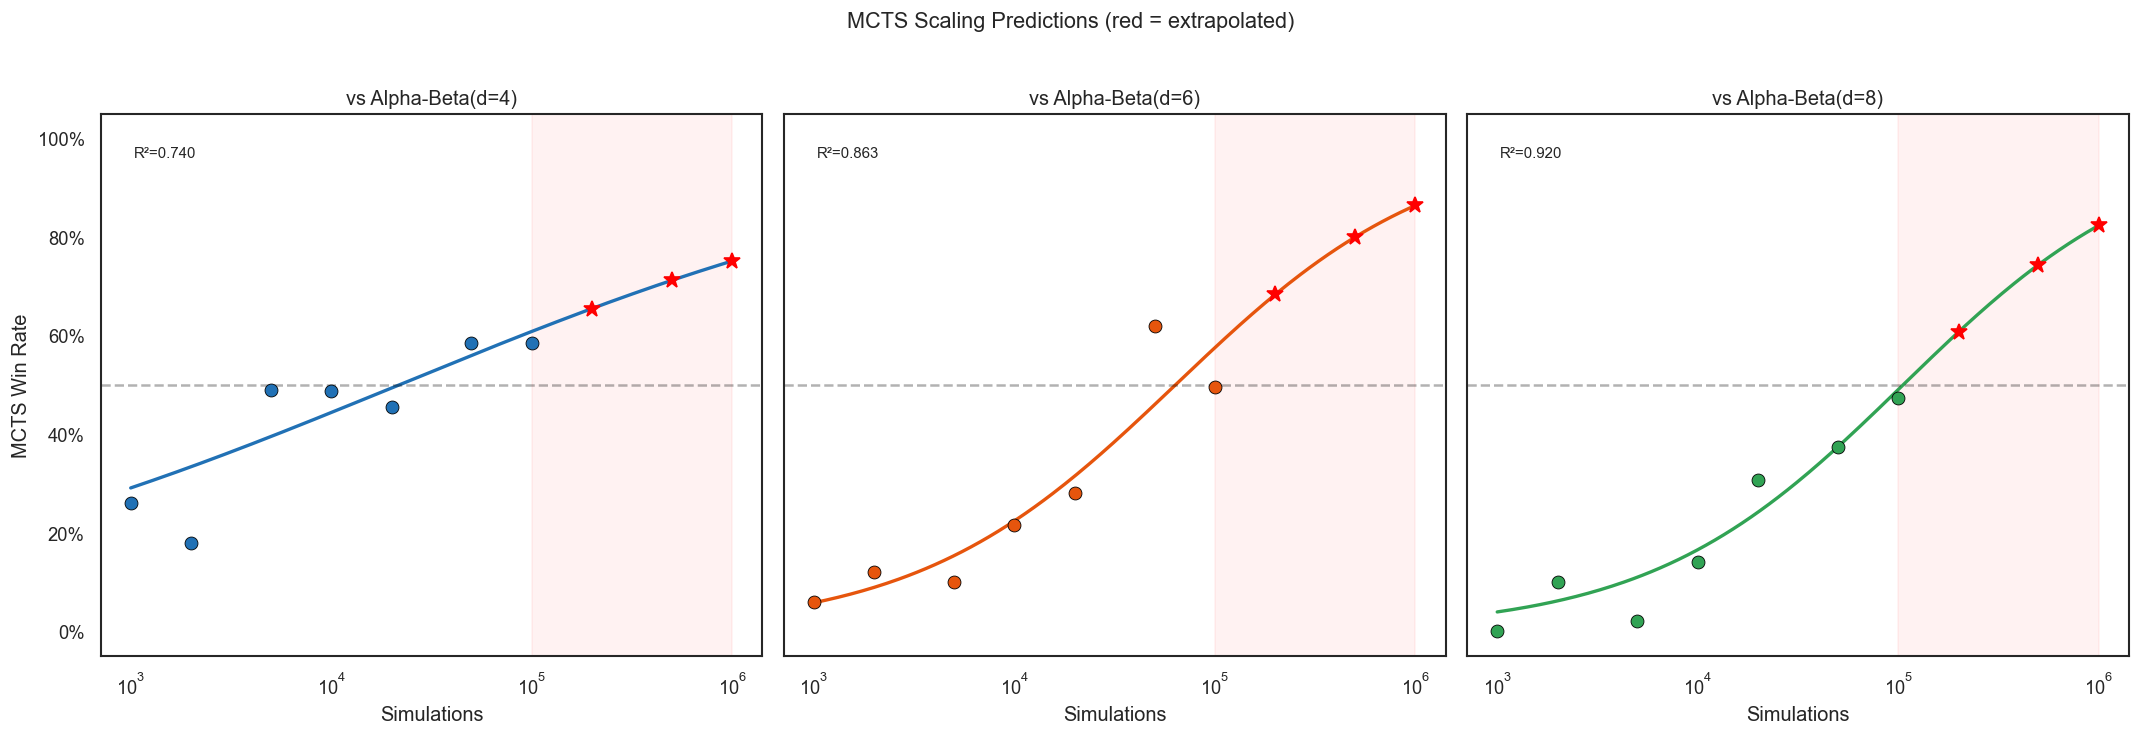

In [37]:
   
mcts_agents=['MCTS(n=1000)','MCTS(n=2000)','MCTS(n=5000)','MCTS(n=10000)','MCTS(n=20000)','MCTS(n=50000)','MCTS(n=100000)']
n_vals=[1000,2000,5000,10000,20000,50000,100000]
fig,axes=plt.subplots(1,3,figsize=(18,6),sharey=True)

print("MCTS Logistic Predictions:\n")
print(f"{'Opponent':<20s}{'R\u00b2':>5s}  {'200k':>14s}  {'500k':>14s}  {'1M':>14s}")
print("-"*72)

for idx,(opp,color) in enumerate([('Alpha-Beta(d=4)','#2171b5'),('Alpha-Beta(d=6)','#e6550d'),('Alpha-Beta(d=8)','#31a354')]):
    ax=axes[idx]; xs,ys,ws=[],[],[]
    for m,nv in zip(mcts_agents,n_vals):
        d2=pw(v2,m,opp)
        if d2: xs.append(np.log10(nv));ys.append(d2['wr']);ws.append(d2['n'])
    xs,ys,ws=np.array(xs),np.array(ys),np.array(ws)
    try:
        popt,pcov=optimize.curve_fit(logistic,xs,ys,p0=[1,-3],sigma=1/np.sqrt(ws),maxfev=5000)
        a,b=popt; r2=1-np.sum((ys-logistic(xs,*popt))**2)/np.sum((ys-ys.mean())**2)
        ax.scatter(10**xs,ys,c=color,s=60,zorder=5,edgecolors='black',linewidth=0.5)
        x_full=np.linspace(xs.min(),6,200);ax.plot(10**x_full,logistic(x_full,a,b),'-',color=color,lw=2)
        pstr=[]
        for pn2 in [200000,500000,1000000]:
            yp=logistic(np.log10(pn2),a,b)
            jac=np.array([np.log10(pn2)*yp*(1-yp),yp*(1-yp)]);se=np.sqrt(jac@pcov@jac)
            ax.plot(pn2,yp,'*',color='red',ms=10,zorder=6)
            pstr.append(f"{yp:.0%} [{max(0,yp-1.96*se):.0%},{min(1,yp+1.96*se):.0%}]")
        print(f"{opp:<20s}{r2:>5.3f}  {pstr[0]:>14s}  {pstr[1]:>14s}  {pstr[2]:>14s}")
        ax.text(0.05,0.92,f'R\u00b2={r2:.3f}',transform=ax.transAxes,fontsize=9)
    except: pass
    ax.axhline(0.5,color='black',ls='--',alpha=0.3);ax.set_xscale('log');ax.set_xlabel('Simulations')
    ax.set_title(f'vs {opp}');ax.set_ylim(-0.05,1.05);ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.axvspan(1e5,1e6,alpha=0.05,color='red')
axes[0].set_ylabel('MCTS Win Rate')
plt.suptitle('MCTS Scaling Predictions (red = extrapolated)',fontsize=13,y=1.02);plt.tight_layout();plt.show()


In [38]:
# Depth extrapolation
print("\nMCTS vs Higher AB Depths (logit-linear extrapolation):\n")
print(f"{'Budget':<22s}{'d=4':>7s}{'d=6':>7s}{'d=8':>7s}{'d=10':>8s}{'d=12':>8s}")
print("-"*55)
for m in ['MCTS(n=10000)','MCTS(n=20000)','MCTS(n=50000)','MCTS(n=100000)']:
    xs2,ys2=[],[]
    for d in [4,6,8]:
        r2=pw(v2,m,f'Alpha-Beta(d={d})')
        if r2: xs2.append(d);ys2.append(r2['wr'])
    if len(xs2)<2: continue
    logit_y=np.log(np.clip(ys2,.01,.99)/(1-np.clip(ys2,.01,.99)))
    sl,ic,_,_,_=stats.linregress(np.array(xs2,dtype=float),logit_y)
    obs=' '.join(f'{y:.0%}' for y in ys2)
    p10=1/(1+np.exp(-(sl*10+ic))); p12=1/(1+np.exp(-(sl*12+ic)))
    print(f"  {m:<22s}{obs:>21s}{p10:>8.0%}{p12:>8.0%}")
print("\nEven MCTS(100k) would likely win <35% against hypothetical AB(d=10).")



MCTS vs Higher AB Depths (logit-linear extrapolation):

Budget                    d=4    d=6    d=8    d=10    d=12
-------------------------------------------------------
  MCTS(n=10000)                   49% 22% 14%      6%      2%
  MCTS(n=20000)                   46% 28% 31%     22%     17%
  MCTS(n=50000)                   58% 62% 37%     32%     23%
  MCTS(n=100000)                  58% 50% 47%     41%     35%

Even MCTS(100k) would likely win <35% against hypothetical AB(d=10).
